In [1]:
import pandas as pd
import numpy as np
from scipy.sparse import hstack, csr_matrix

from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.dummy import DummyClassifier

from sklearn.feature_selection import f_classif
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, PowerTransformer, KBinsDiscretizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedGroupKFold, PredefinedSplit
from sklearn.metrics import classification_report, f1_score, accuracy_score, silhouette_score, ConfusionMatrixDisplay

import optuna

/home/thomas/projects/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# 1. Data Understanding and Preparation

In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [3]:
df = pd.read_csv(Path("/mnt/data/datasets/spotify_tracks/tracks.csv"))

## 1.1 Exploratory Data Analysis

### 1.1.1 Dataset Overview

In [4]:
df.head()

,Unnamed: 0,track_name,track_id,album_name,album_id,album_image,album_release_date,album_release_date_precision,artist_name,artist_id,popularity,duration_ms,explicit,preview_url,genre,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,database_shard_id,duration_seconds,duration_minutes
0,0,"Divenire: No. 9, Fly - Intouchables",5u5scm02d5wN6nWFKuqEUK,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,2,265653,False,https://p.scdn.co/mp3-preview/81f71ca4ea95503e...,ambient,0.990,0.184,0.03270,0.877,1,0.0996,-28.184,0,0.0366,168.133,3,0.0351,0,265.653,4.427550
1,1,Spiegel im Spiegel - Heaven,1wV4SNFEXWawsyjBCGwkiw,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,0,349120,False,https://p.scdn.co/mp3-preview/040ea9c848708316...,ambient,0.985,0.250,0.01480,0.971,5,0.0669,-30.646,1,0.0375,136.864,5,0.0394,0,349.120,5.818667
2,2,Truman Sleeps - The Trumanshow,4gYub3T80gNfU9F4Df98AR,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,1,128039,False,https://p.scdn.co/mp3-preview/e9a7cd955c89d480...,ambient,0.993,0.269,0.02110,0.883,5,0.1390,-24.620,0,0.0395,69.487,4,0.0411,0,128.039,2.133983
3,3,The Heart Askes Pleasure First - The Piano,6sXRgSAQsySTM7kH1pM07Y,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,0,190960,False,https://p.scdn.co/mp3-preview/9a33da62792f8277...,ambient,0.995,0.230,0.13800,0.885,4,0.1010,-19.591,0,0.0371,165.197,3,0.1710,0,190.960,3.182667
4,4,3 Gymnopédies: I. Lent et douloureux,7Eytd0e0mNFiSWIE132H76,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,4,338933,False,https://p.scdn.co/mp3-preview/d31979ca20bbd759...,ambient,0.995,0.611,0.00162,0.967,7,0.0817,-37.782,1,0.2860,134.237,3,0.5080,0,338.933,5.648883


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2112746 entries, 0 to 2112745
Data columns (total 30 columns):
 #   Column                        Dtype  
---  ------                        -----  
 0   Unnamed: 0                    int64  
 1   track_name                    str    
 2   track_id                      str    
 3   album_name                    str    
 4   album_id                      str    
 5   album_image                   str    
 6   album_release_date            str    
 7   album_release_date_precision  str    
 8   artist_name                   str    
 9   artist_id                     str    
 10  popularity                    int64  
 11  duration_ms                   int64  
 12  explicit                      bool   
 13  preview_url                   str    
 14  genre                         str    
 15  acousticness                  float64
 16  danceability                  float64
 17  energy                        float64
 18  instrumentalness              flo

### 1.1.2 Dataset Quality

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.isnull().sum()

Unnamed: 0                           0
track_name                           6
track_id                             0
album_name                           6
album_id                             0
album_image                        491
album_release_date                   0
album_release_date_precision         0
artist_name                         17
artist_id                            0
popularity                           0
duration_ms                          0
explicit                             0
preview_url                     325237
genre                                0
acousticness                         0
danceability                         0
energy                               0
instrumentalness                     0
key                                  0
liveness                             0
loudness                             0
mode                                 0
speechiness                          0
tempo                                0
time_signature           

In [4]:
df = df.drop(columns=['Unnamed: 0', 'database_shard_id', 'preview_url', 'album_image', 'album_release_date', 'album_release_date_precision', 'duration_ms', 'duration_minutes'])
df = df.dropna()

In [5]:
df["explicit"] = df["explicit"].astype(int)

### 1.1.3 Feature Relationship and Distribution

In [21]:
df.describe()

,popularity,explicit,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,duration_seconds
count,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06
mean,1.377669e+01,4.922896e-02,3.921951e-01,5.285403e-01,5.833899e-01,2.188440e-01,5.248907e+00,2.245107e-01,-1.025282e+01,6.620721e-01,8.522024e-02,1.202606e+02,3.873687e+00,4.874551e-01,2.494315e+02
std,1.463679e+01,2.163458e-01,3.669644e-01,1.797388e-01,2.759466e-01,3.469520e-01,3.532854e+00,2.025184e-01,5.799929e+00,4.730039e-01,1.185059e-01,2.977370e+01,4.701903e-01,2.726161e-01,1.453008e+02
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.970000e-05,0.000000e+00,0.000000e+00,2.960000e-03,-5.810000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.860000e-01
25%,1.000000e+00,0.000000e+00,2.210000e-02,4.040000e-01,3.700000e-01,1.180000e-06,2.000000e+00,9.770000e-02,-1.290100e+01,0.000000e+00,3.570000e-02,9.711000e+01,4.000000e+00,2.560000e-01,1.795000e+02
50%,9.000000e+00,0.000000e+00,2.890000e-01,5.390000e-01,6.130000e-01,8.260000e-04,5.000000e+00,1.370000e-01,-8.900000e+00,1.000000e+00,4.720000e-02,1.199840e+02,4.000000e+00,4.840000e-01,2.268815e+02
75%,2.200000e+01,0.000000e+00,7.600000e-01,6.630000e-01,8.260000e-01,4.060000e-01,8.000000e+00,2.910000e-01,-6.117000e+00,1.000000e+00,7.850000e-02,1.385590e+02,4.000000e+00,7.150000e-01,2.878800e+02
max,1.000000e+02,1.000000e+00,9.960000e-01,9.950000e-01,1.000000e+00,1.000000e+00,1.100000e+01,1.000000e+00,6.172000e+00,1.000000e+00,9.690000e-01,2.499930e+02,5.000000e+00,1.000000e+00,7.200006e+03


In [10]:
print(df['genre'].value_counts().to_string())

genre
classical            48143
blues                45752
indian               43616
german               43002
french               40832
country              38847
british              38476
alt-rock             37065
disco                34808
brazil               34482
opera                34056
turkish              33997
pop-film             32268
dance                32059
jazz                 31340
ambient              30898
gospel               30422
latin                30368
spanish              30298
folk                 29167
funk                 28505
guitar               27087
bluegrass            27073
k-pop                26456
j-pop                26114
swedish              25838
dub                  25670
acoustic             25669
children             25597
new-age              25164
mpb                  25108
anime                24623
black-metal          23511
dancehall            23477
forro                23266
cantopop             23036
death-metal          2

In [6]:
df_numeric = df.select_dtypes(include='number')

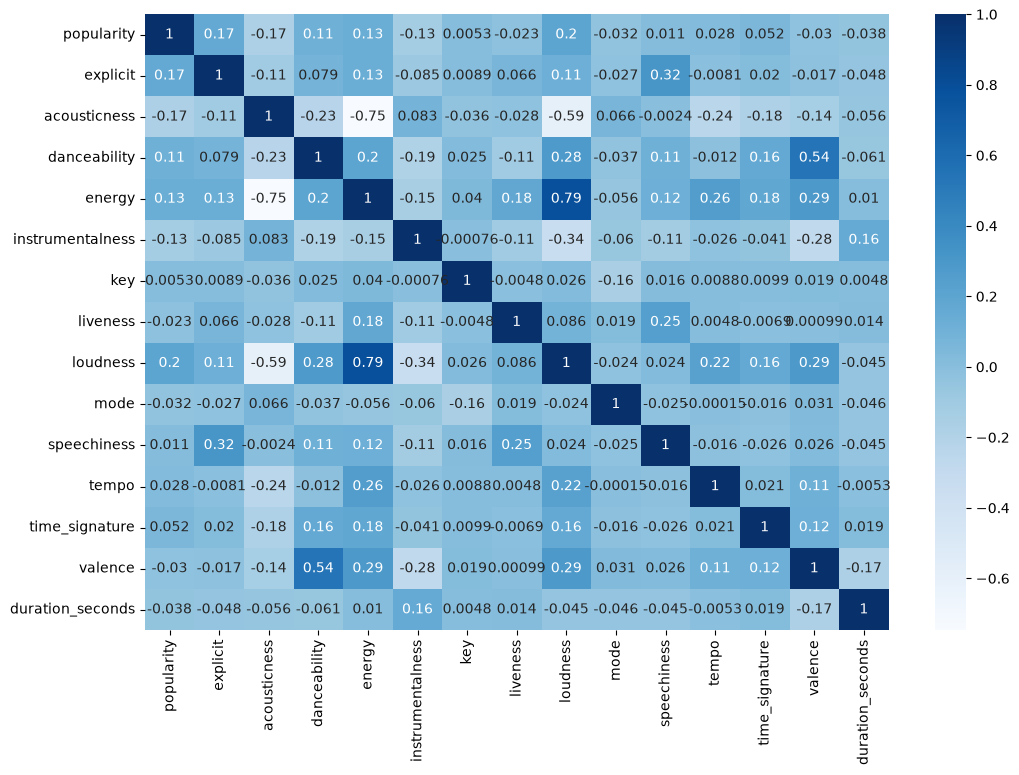

In [32]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df_numeric.corr(),
    annot=True,
    cmap='Blues'
)

plt.show()

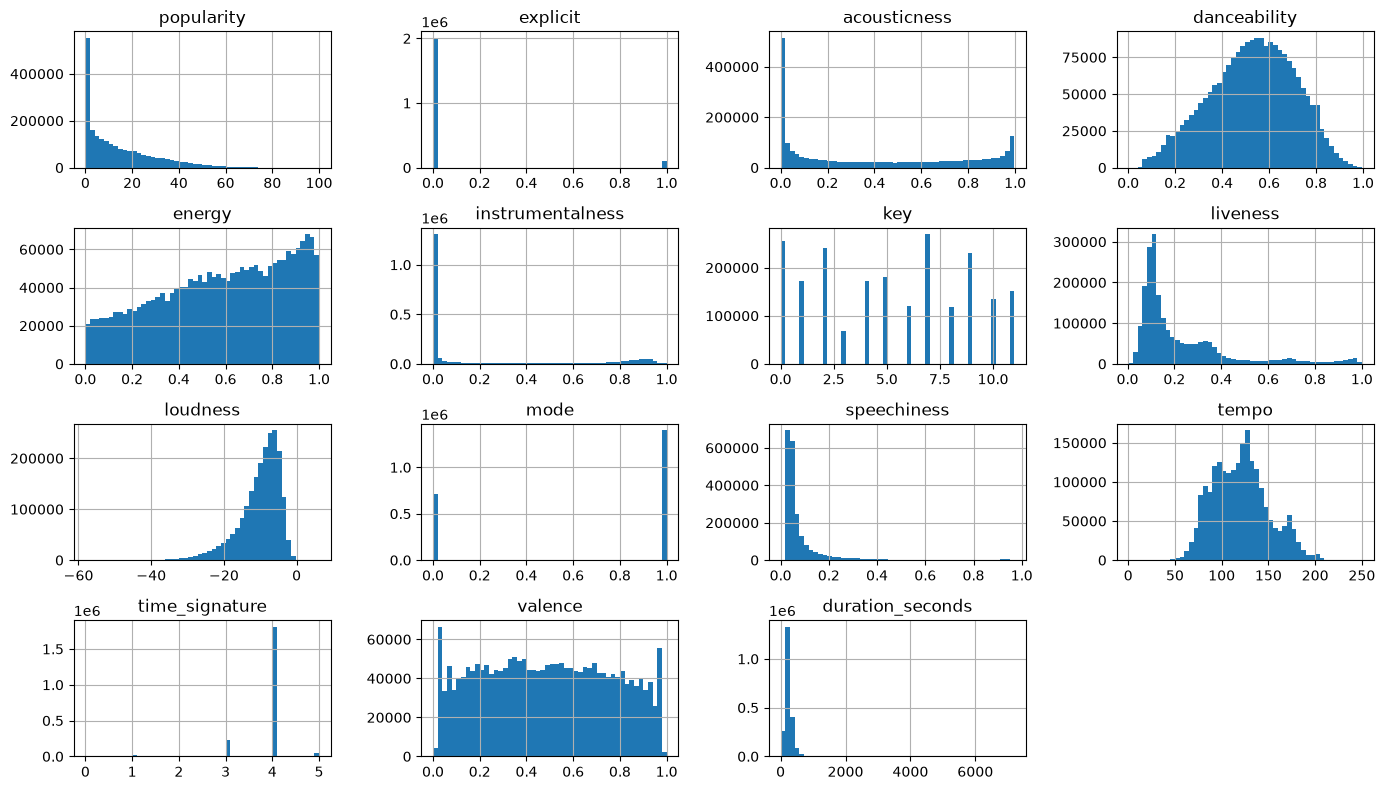

In [33]:
df_numeric.hist(bins=50, figsize=(14, 8))

plt.tight_layout()
plt.show()

array([[<Axes: xlabel='popularity', ylabel='popularity'>,
        <Axes: xlabel='acousticness', ylabel='popularity'>,
        <Axes: xlabel='danceability', ylabel='popularity'>,
        <Axes: xlabel='energy', ylabel='popularity'>,
        <Axes: xlabel='instrumentalness', ylabel='popularity'>,
        <Axes: xlabel='key', ylabel='popularity'>,
        <Axes: xlabel='liveness', ylabel='popularity'>,
        <Axes: xlabel='loudness', ylabel='popularity'>,
        <Axes: xlabel='mode', ylabel='popularity'>,
        <Axes: xlabel='speechiness', ylabel='popularity'>,
        <Axes: xlabel='tempo', ylabel='popularity'>,
        <Axes: xlabel='time_signature', ylabel='popularity'>,
        <Axes: xlabel='valence', ylabel='popularity'>,
        <Axes: xlabel='duration_seconds', ylabel='popularity'>],
       [<Axes: xlabel='popularity', ylabel='acousticness'>,
        <Axes: xlabel='acousticness', ylabel='acousticness'>,
        <Axes: xlabel='danceability', ylabel='acousticness'>,
        <Ax

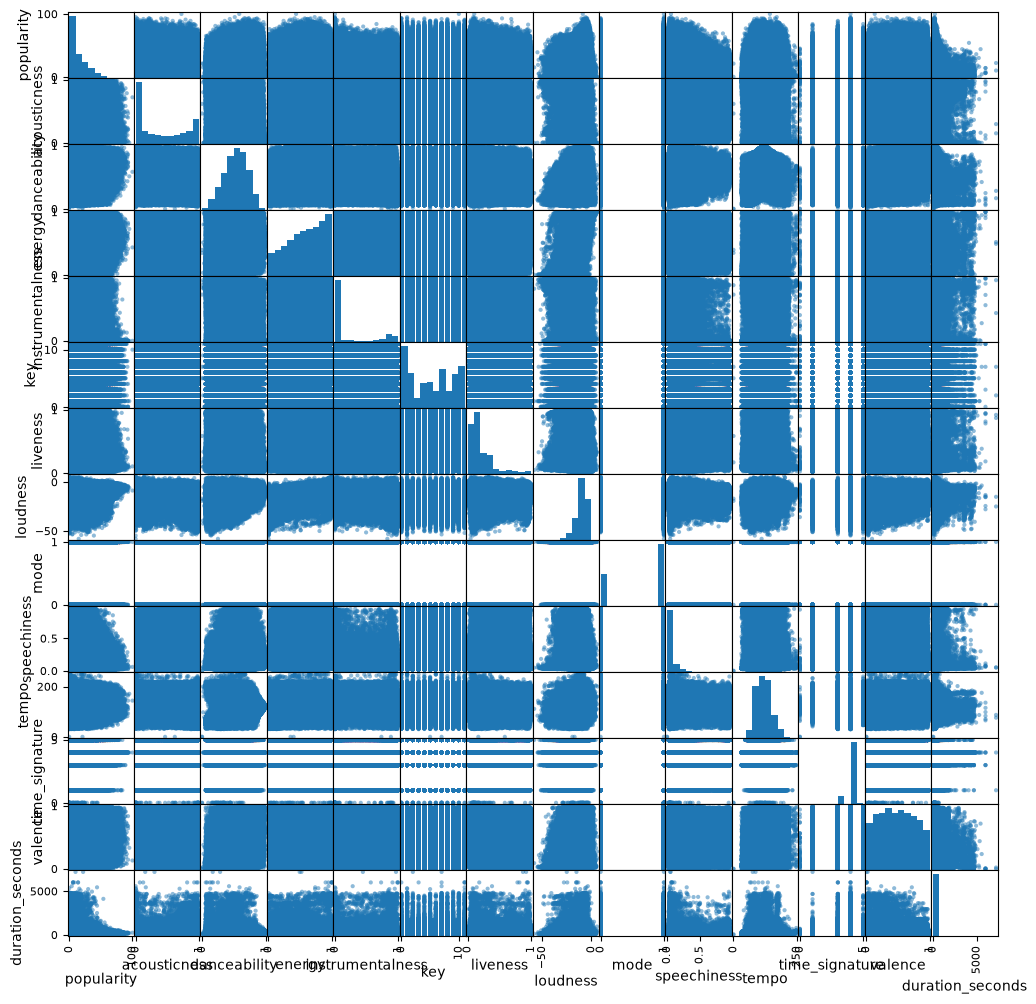

In [132]:
pd.plotting.scatter_matrix(df_numeric, figsize = (12,12))

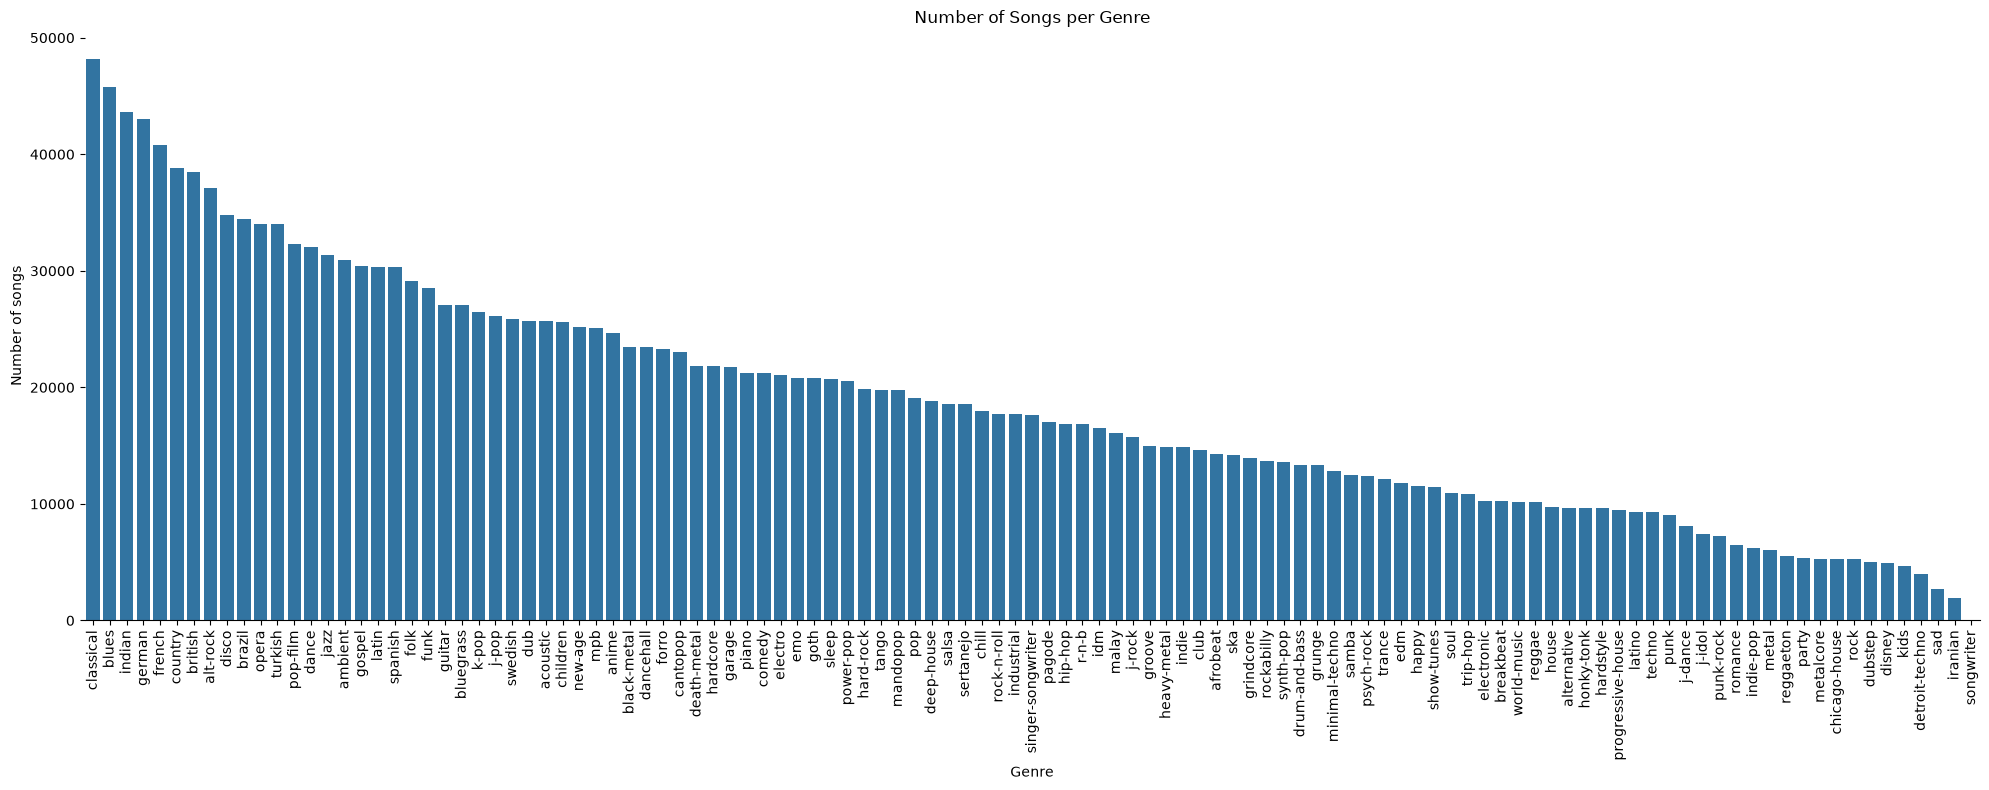

In [7]:
plt.figure(figsize=(20, 8))

genre_order = df["genre"].value_counts().index

ax = sns.countplot(
    data=df,
    x="genre",
    order=genre_order
)

plt.xticks(rotation=90)
plt.xlabel("Genre")
plt.ylabel("Number of songs")
plt.title("Number of Songs per Genre")
sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

In [25]:
print(f'Number of unique tracks: {df['track_id'].nunique()}')
print(f"Number of unique albums: {df['album_id'].nunique()}")
print(f"Number of unique artists: {df['artist_name'].nunique()}")
print(f"Number of unique genres: {df['genre'].nunique()}")

Number of unique tracks: 2112720
Number of unique albums: 464274
Number of unique artists: 77410
Number of unique genres: 113


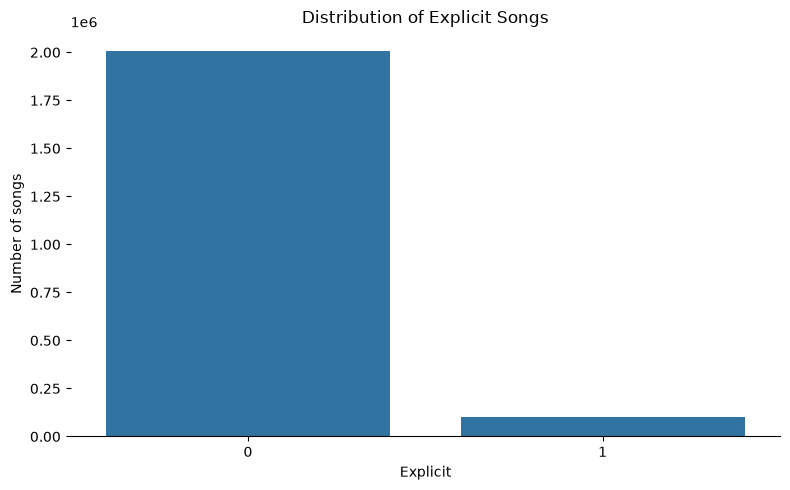

In [8]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="explicit",
    order=df["explicit"].value_counts().index
)

plt.xlabel("Explicit")
plt.ylabel("Number of songs")
plt.title("Distribution of Explicit Songs")

sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

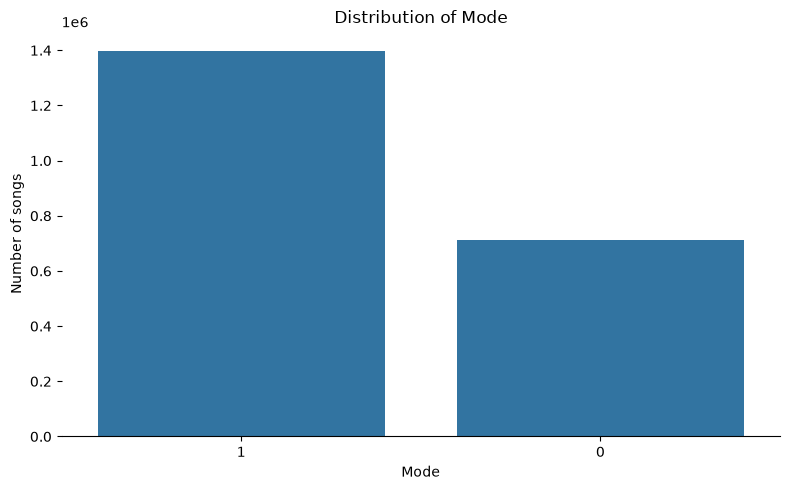

In [12]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="mode",
    order=df["mode"].value_counts().index
)

plt.xlabel("Mode")
plt.ylabel("Number of songs")
plt.title("Distribution of Mode")

sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

### 1.1.4 Feature Class Balance

The histograms above show that some continous numerical features have asymmetric distributions. Skewness describes the asymmetry of a data distribution around its mean.
This could negatively impact the performance of models that assume normally distributed data or are sensitive to the variance of input features, such as linear regression, principal component analysis (PCA), and support vector machines (SVMs).
- **Positive skewness (right-skewed):** the distribution has a longer tail towards higher values.
- **Negative skewness (left-skewed):** the distribution has a longer tail towards lower values.

Based on the histograms, the following features appear to be positively skewed:
- `duration_seconds`
- `liveness`
- `instrumentalness`
- `popularity`

The following features appear to be negatively skewed:
- `energy`
- `loudness`

The skewness of `acousticness` is less clear from the histogram alone and will be investigated further in the next step.

In [9]:
df_numeric.skew()

popularity          1.193135
explicit            4.167139
acousticness        0.372808
danceability       -0.218409
energy             -0.324793
instrumentalness    1.193576
key                -0.001299
liveness            1.960634
loudness           -1.393427
mode               -0.685289
speechiness         4.772669
tempo               0.360192
time_signature     -3.139475
valence             0.047022
duration_seconds    8.493171
dtype: float64

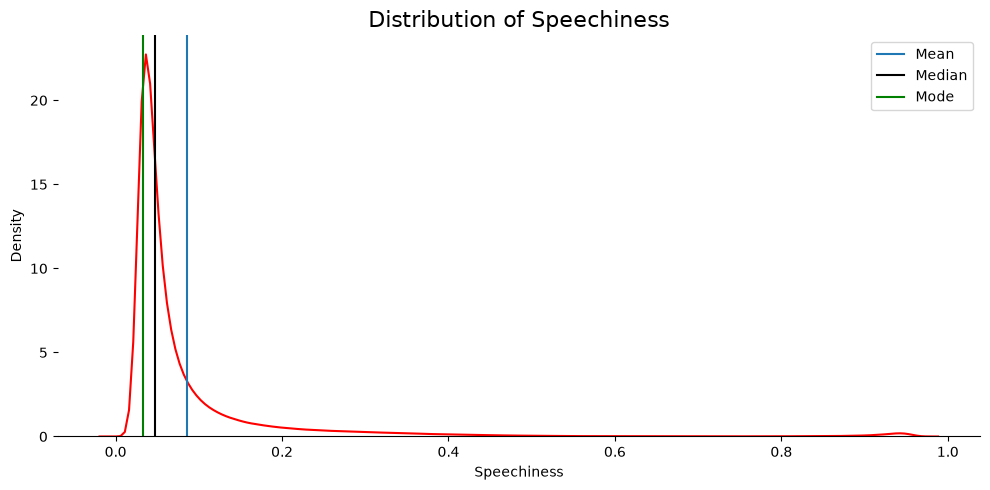

In [16]:
# Find the mean, median, mode
mean_value = df["speechiness"].mean()
median_value = df["speechiness"].median()
mode_value = df["speechiness"].mode().iloc[0]

plt.figure(figsize=(10, 5))
sns.kdeplot(x=df['speechiness'], color="red")

# Add vertical lines at the position of mean, median, mode
plt.axvline(mean_value, label="Mean")
plt.axvline(median_value, color="black", label="Median")
plt.axvline(mode_value, color="green", label="Mode")

plt.title("Distribution of Speechiness", fontsize=16)
plt.xlabel("Speechiness")
plt.ylabel("Density")
sns.despine(top=True, right=True, left=True)
plt.legend()
plt.tight_layout()
plt.show()


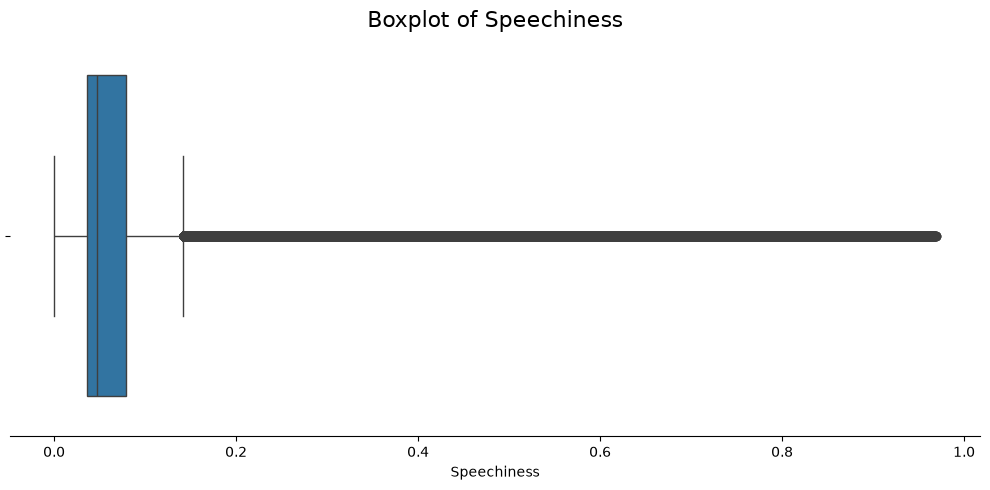

In [17]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["speechiness"])

plt.title("Boxplot of Speechiness", fontsize=16)
plt.xlabel("Speechiness")
sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

The KDE plot (*continous*) and boxplot of speechiness confirm its positive skewness of 4.77, as we saw on the histogram (*bins*). Most observations are concentrated at **lower values**, with a **long tail** extending towards higher values, on the right side of the peak.

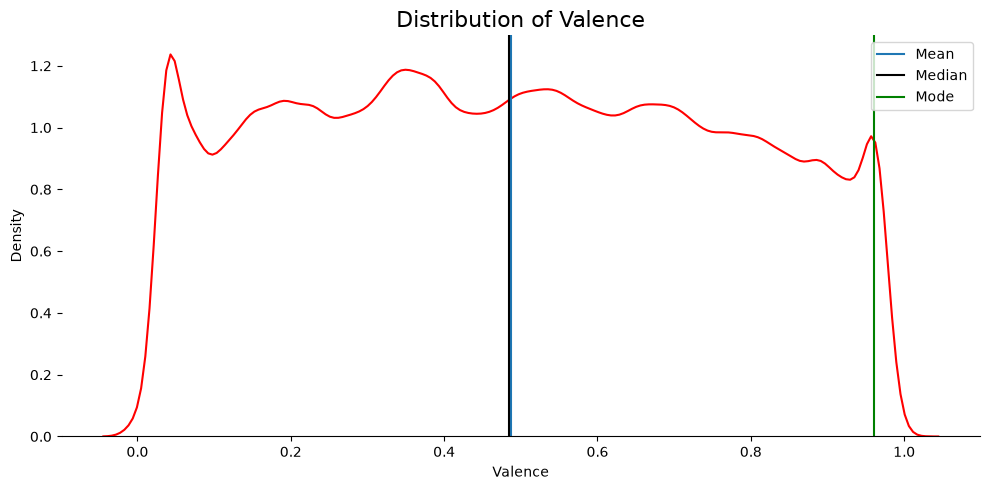

In [19]:
# Find the mean, median, mode
mean_value = df["valence"].mean()
median_value = df["valence"].median()
mode_value = df["valence"].mode().iloc[0]

plt.figure(figsize=(10, 5))
sns.kdeplot(x=df['valence'], color="red")

# Add vertical lines at the position of mean, median, mode
plt.axvline(mean_value, label="Mean")
plt.axvline(median_value, color="black", label="Median")
plt.axvline(mode_value, color="green", label="Mode")

plt.title("Distribution of Valence", fontsize=16)
plt.xlabel("Valence")
plt.ylabel("Density")
sns.despine(top=True, right=True, left=True)
plt.legend()
plt.tight_layout()
plt.show()


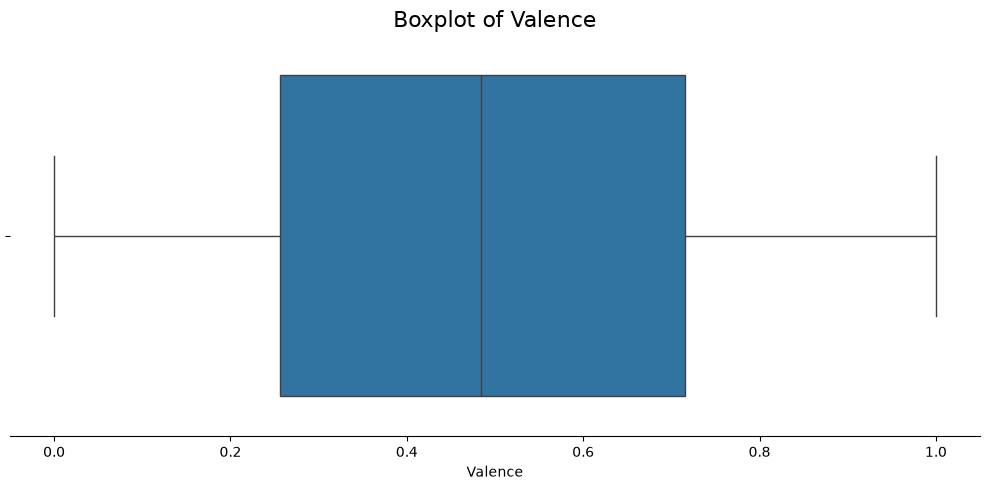

In [20]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["valence"])

plt.title("Boxplot of Valence", fontsize=16)
plt.xlabel("Valence")
sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

The KDE plot and boxplot of valence show a relatively symmetric distribution, consistent with its near-zero skewness of 0.05, as observed in the histogram. The mean and median are close together, and the distribution does not show a pronounced tail towards either lower or higher values.

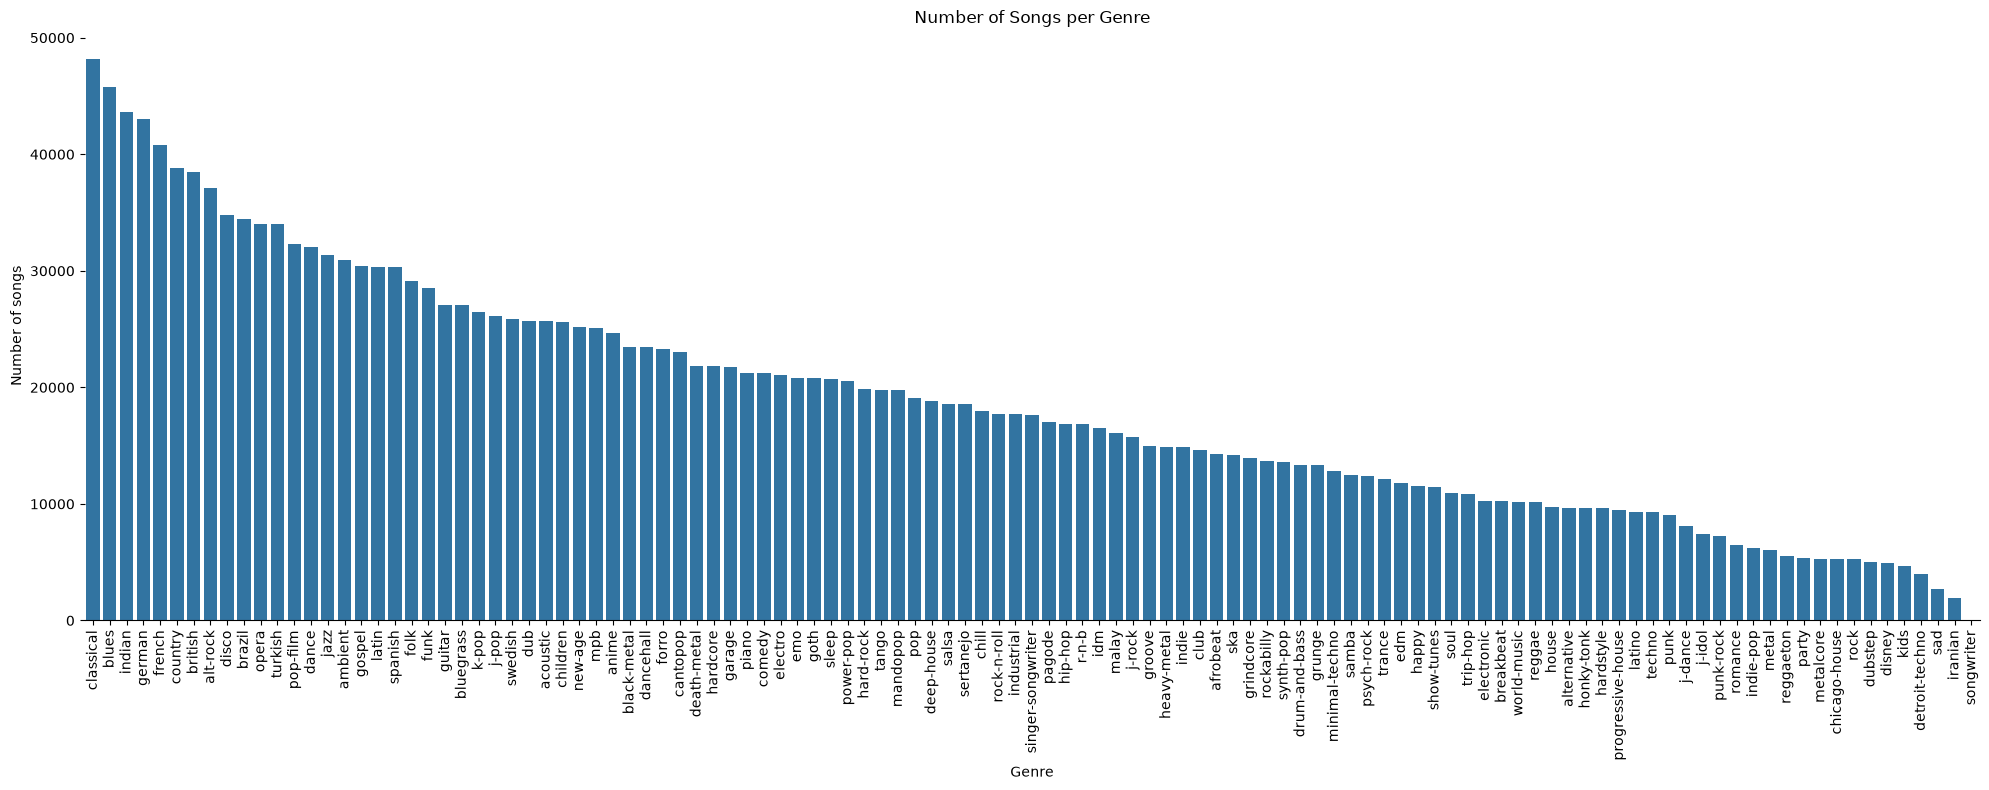

In [13]:
plt.figure(figsize=(20, 8))

genre_order = df["genre"].value_counts().index

ax = sns.countplot(
    data=df,
    x="genre",
    order=genre_order
)

plt.xticks(rotation=90)
plt.xlabel("Genre")
plt.ylabel("Number of songs")
plt.title("Number of Songs per Genre")
sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

The countplot shows the distribution of tracks across genres (113), ordered from most frequent to least frequent. The number of tracks varies considerably between genres: classical is the most represented genre, with 48,143 tracks, whereas songwriter has only 66 tracks. This indicates a substantial class imbalance, which may cause the classification model to perform better on well-represented genres than on underrepresented ones.

### 1.1.5 Correlation and Multicollinearity

In [7]:
le = LabelEncoder()

In [8]:
df['genre'] = le.fit_transform(df["genre"])

In the next step we calculate the **ANOVA F-statistic**, as our input variables are numerical and output variables are non-ordinal categorical. This informs us what features correlate highly with the label `genre`.

For more information, see [How to Choose a Feature Selection Method For Machine Learning](https://machinelearningmastery.com/feature-selection-with-real-and-categorical-data/).

In [11]:
f_statistic, _ = f_classif(df_numeric, df['genre'])

anova_df = pd.DataFrame({
    "feature": df_numeric.columns,
    "F-value": f_statistic
}).sort_values("F-value", ascending=False)

anova_df

,feature,F-value
2,acousticness,15341.381870
4,energy,12725.056429
10,speechiness,12482.180857
8,loudness,11721.134834
3,danceability,9761.926486
5,instrumentalness,9546.465465
13,valence,7156.577619
0,popularity,5811.257996
1,explicit,4485.743419
14,duration_seconds,2017.891713


The highest F-values observed are `acousticness`, `speechiness` and `energy`.

We calculate the **Variance Inflation Factor** (VIF) to detect multicollinearity between the numerical input variables. This indicates whether some features contain overlapping information, and could therefore mislead the model.

In [12]:
vif_df = pd.DataFrame({
    "feature": df_numeric.columns,
    "VIF": [
        variance_inflation_factor(df_numeric.values, i)
        for i in range(df_numeric.shape[1])
    ]
}).sort_values("VIF", ascending=False)

vif_df

,feature,VIF
4,energy,4.806935
8,loudness,3.310650
2,acousticness,2.554418
13,valence,1.739758
3,danceability,1.667658
5,instrumentalness,1.315740
10,speechiness,1.268932
1,explicit,1.162053
7,liveness,1.160771
0,popularity,1.105422


A VIF value equal to 1 indicates **no multicollinearity**, while a VIF between 1 and 5 indicates a **moderate** level of multicollinearity. A VIF greater than 5 indicates potentially **problematic** multicollinearity.

The highest VIF values were observed for `energy` and `loudness`. Both values are below the threshold of 5, indicating that there is no significant multicollinearity between the input features. Therefore, both features can remain in the dataset.

## 1.2 Data Preparation

### 1.2.1 Feature Engineering

We remove the `popularity` feature because it reflects a track's popularity rather than its intrinsic audio characteristics or textual metadata. 

Since our objective is to build a model that generalizes to unseen data, relying on popularity could be problematic, as it can change over time and may introduce biases towards more popular tracks.

However, popularity could be useful in a recommendation system for a platform such as Spotify or Deezer, where it provides additional information about listening trends and user preferences. In that context, popularity data could be regularly updated to reflect changing trends.

In [9]:
df = df.drop(columns='popularity')

In [10]:
df['duration_seconds'] = df['duration_seconds'].round().astype(int)

In [11]:
df["album_songs"] = (
    df.groupby("album_id")["track_name"]
    .transform("count")
)

In [12]:
df['artist_songs'] = (
    df.groupby("artist_id")["track_name"]
    .transform("count")
)

In [13]:
df["song_avg_duration"] = (
    df.groupby("artist_id")["duration_seconds"].transform("sum")
    / df["artist_songs"]
)

In [59]:
df["song_std_duration"] = (
    df.groupby("artist_id")["duration_seconds"].transform("std").fillna(0)
)

In [15]:
df["album_song_avg_duration"] = (
    df.groupby("album_id")["duration_seconds"].transform("sum")
    / df["album_songs"]
)

In [16]:
df["artist_album_count"] = (
    df.groupby("artist_id")["album_id"]
      .transform("nunique")
)

Our dataset also consists of categorical features: `key` and `time_signature`, which we convert using one-hot encoding into numerical features. This is a better option than ordinal encoding, as it prevents models from assuming an incorrect order between categories

In [60]:
ohe_key = OneHotEncoder(sparse_output=False).set_output(transform='pandas')
ohe_time_signature = OneHotEncoder(sparse_output=False).set_output(transform='pandas')

In [61]:
df_key = ohe_key.fit_transform(df[['key']])
df_time_signature = ohe_time_signature.fit_transform(df[['time_signature']])

In [62]:
df_encoded = pd.concat(
    [
        df.drop(columns=["key", "time_signature"]),
        df_key,
        df_time_signature,
    ],
    axis=1
)

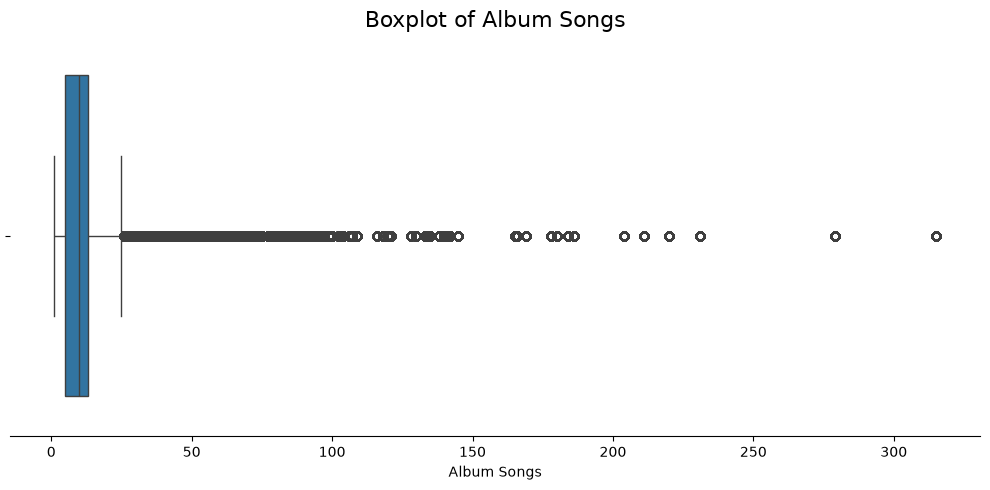

In [17]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['album_songs'])

plt.title("Boxplot of Album Songs", fontsize=16)
plt.xlabel("Album Songs")
sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

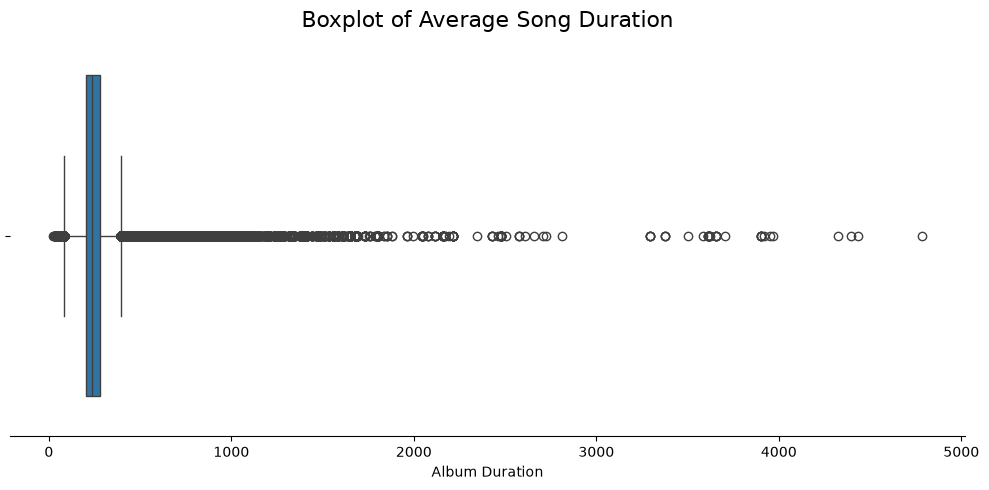

In [19]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['song_avg_duration'])

plt.title("Boxplot of Average Song Duration", fontsize=16)
plt.xlabel("Album Duration")
sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

### 1.2.2 Feature Transformation

In [63]:
X = df_encoded.drop(columns='genre')
y = df_encoded['genre']

In [22]:
def detect_outliers(ds: pd.Series):
    Q1 = ds.quantile(0.25)
    Q3 = ds.quantile(0.75)
    IQR = Q3 - Q1

    outliers = (
        (ds < Q1 - 1.5 * IQR) |
        (ds > Q3 + 1.5 * IQR)
    )

    return outliers

We use the Interquartile Range (IQR) method to identify potential outliers in our dataset. The features `album_songs` and `album_duration` contain 121,074 (5.73%) and 105,243 (4.98%) potential outliers, respectively. We then inspect these observations to better understand their characteristics and determine whether they represent unusual but valid data points.

In [23]:
album_songs_outliers = detect_outliers(X['album_songs'])
print(f"{album_songs_outliers.sum():,} - potential outliers ({album_songs_outliers.mean():.2%})")

121,074 - potential outliers (5.73%)


In [24]:
avg_album_song_duration_outliers = detect_outliers(X['song_avg_duration'])
print(f"{avg_album_song_duration_outliers.sum():,} - potential outliers ({avg_album_song_duration_outliers.mean():.2%})")

111,246 - potential outliers (5.27%)


In [25]:
outlier_songs = df.loc[
    album_songs_outliers,
    ["track_name", "album_name", "artist_name", "album_songs", "genre"]
].sort_values("album_songs", ascending=False)

display(outlier_songs.head(10))
display(outlier_songs.tail(10))

,track_name,album_name,artist_name,album_songs,genre
44791,"Heinichen: Kleines harmonisches Labyrinth, BWV...",Bach: Complete Organ Works (Analogue Version -...,Johann David Heinichen,315,39
44774,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,Nicolaus Vetter,315,39
44775,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,Nicolaus Vetter,315,39
44776,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,Nicolaus Vetter,315,39
44778,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,Nicolaus Vetter,315,39
44779,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,Nicolaus Vetter,315,39
44780,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,Nicolaus Vetter,315,39
44781,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,Nicolaus Vetter,315,39
44782,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,Nicolaus Vetter,315,39
44784,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,Nicolaus Vetter,315,39


,track_name,album_name,artist_name,album_songs,genre
934056,"How Long, How Long Blues",Atomic Boogie,Big Joe Turner,26,92
934055,Rock Of Gibraltar Blues,Atomic Boogie,Big Joe Turner,26,92
934054,Howling Winds,Atomic Boogie,Big Joe Turner,26,92
934053,Whistle Stop Blues,Atomic Boogie,Big Joe Turner,26,92
934052,It's A Low Down Dirty Shame,Atomic Boogie,Big Joe Turner,26,92
2111869,Ağla Ağla - Live,Söz & Müzik: Tan Taşçı (Live),Tan Taşçı,26,111
2111868,Ziyan & Doğum Günü - Live,Söz & Müzik: Tan Taşçı (Live),Tan Taşçı,26,111
2111867,Yalvarırım - Live,Söz & Müzik: Tan Taşçı (Live),Tan Taşçı,26,111
140341,Born In a Trunk - Instrumental,"Very 'Eavy, Very 'Umble (Expanded Version)",Uriah Heep,26,47
140304,Dreammare - Alternative Version,"Very 'Eavy, Very 'Umble (Expanded Version)",Uriah Heep,26,47


In [138]:
le.inverse_transform([39, 92, 111, 47])

array(['german', 'rockabilly', 'turkish', 'hard-rock'], dtype=object)

In [26]:
outlier_songs = df.loc[
    album_songs_outliers,
    ["track_name", "album_name", "artist_name", "song_avg_duration", "genre"]
].sort_values("song_avg_duration", ascending=False)

display(outlier_songs.head(10))
display(outlier_songs.tail(10))

,track_name,album_name,artist_name,song_avg_duration,genre
75626,Symphony No. 2 in E Minor: II. Andante semplice,Wiener Konzerte 1944-1954,Wilhelm Furtwängler,1199.500000,39
75625,Symphony No. 2 in E Minor: I. Assai moderato,Wiener Konzerte 1944-1954,Wilhelm Furtwängler,1199.500000,39
75622,Symphony No. 2 in E Minor: III. Allegro,Wiener Konzerte 1944-1954,Wilhelm Furtwängler,1199.500000,39
75621,Symphony No. 2 in E Minor: IV. Langsam,Wiener Konzerte 1944-1954,Wilhelm Furtwängler,1199.500000,39
809790,Abhogi,The Raga Guide,Hariprasad Chaurasia,1107.142857,16
809896,Pilu,The Raga Guide,Hariprasad Chaurasia,1107.142857,16
810099,Lalit,The Raga Guide,Hariprasad Chaurasia,1107.142857,16
810061,Basant,The Raga Guide,Hariprasad Chaurasia,1107.142857,16
809785,Bhupali,The Raga Guide,Hariprasad Chaurasia,1107.142857,16
810222,Bilaskhani Todi,The Raga Guide,Hariprasad Chaurasia,1107.142857,16


,track_name,album_name,artist_name,song_avg_duration,genre
822308,Career Overview,West Side Horizons,Despise You,47.918919,42
822309,Busted Outlook,West Side Horizons,Despise You,47.918919,42
822311,De Volada Decision,West Side Horizons,Despise You,47.918919,42
822285,Hand Me Down Existencia,West Side Horizons,Despise You,47.918919,42
822284,Been Lead,West Side Horizons,Despise You,47.918919,42
822269,I End Me,West Side Horizons,Despise You,47.918919,42
822270,No More....feelings,West Side Horizons,Despise You,47.918919,42
822276,One More Rosary,West Side Horizons,Despise You,47.918919,42
822312,Unmoved / Complacent,West Side Horizons,Despise You,47.918919,42
1636010,Daughters of Triton - Remastered 2014,Walt Disney Records The Legacy Collection: The...,Daughters of Triton,44.333333,26


In [27]:
le.inverse_transform([39, 16, 42, 26])

array(['german', 'classical', 'grindcore', 'disney'], dtype=object)

### 1.2.3 Data Splitting and Stratification

We split our dataset into three subsets: 80% for training, 10% for validation, and 10% for testing. To achieve this while minimizing data leakage, we used StratifiedGroupKFold, with album_id as the grouping variable and genre as the stratification target.

**Grouping by album** ensures that all tracks belonging to the same album assigned to the same subset. This prevents tracks from the same album from appearing in both the training and evaluation sets, reducing the risk of data leakage, and so overly optimistic performance estimates caused by similarities between tracks from the same album.

**Stratification** by genre helps preserve the genre distribution across the subsets, ensuring each subset remains reasonably representative of the overall dataset.

In [64]:
groups = X['album_id']

In [65]:
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [66]:
train_idx, remaining_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
y_train = y.iloc[train_idx]

X_remaining = X.iloc[remaining_idx]
y_remaining = y.iloc[remaining_idx]

In [67]:
groups_remaining = groups.iloc[remaining_idx]

In [68]:
splitter_remaining = StratifiedGroupKFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

In [69]:
validation_idx, test_idx = next(
    splitter_remaining.split(
        X_remaining,
        y_remaining,
        groups=groups_remaining
    )
)

X_validation = X_remaining.iloc[validation_idx]
y_validation = y_remaining.iloc[validation_idx]

X_test = X_remaining.iloc[test_idx]
y_test = y_remaining.iloc[test_idx]

In [81]:
print(f"Train:      {len(X_train):,} ({len(X_train) / len(X):.1%})")
print(f"Validation: {len(X_validation):,} ({len(X_validation) / len(X):.1%})")
print(f"Test:       {len(X_test):,} ({len(X_test) / len(X):.1%})")

Train:      1,690,176 (80.0%)
Validation: 211,272 (10.0%)
Test:       211,272 (10.0%)


### 1.2.4 Feature Extraction using TF-IDF

We also used the `track_name` and `album_name` features, as their text may contain useful information for predicting a track's genre. We applied TF-IDF to the combined text ({track_name} {album_name}) to represent words based on their frequency within a document and their relative rarity across the dataset. This allows the model to identify textual patterns that may be associated with particular genres.

In [28]:
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(token_pattern=r"(?u)\b[^\W\d_]+\b")),
    ("clf", MultinomialNB())
])

In [27]:
parameters = {
    "tfidf__ngram_range": [(1, 1), (1, 2), (1,3)],
    "tfidf__max_features": [5000],
    "tfidf__min_df": [2, 3, 5, 8, 15, 20, 30],
    "tfidf__max_df": [0.5, 0.75],
}

In [ ]:
#X_tuning = np.concatenate([
#    X_train["track_name"].astype(str).to_numpy(),
#    X_validation["track_name"].astype(str).to_numpy()
#])

#X_tuning = np.concatenate([
#    X_train["album_name"].astype(str).to_numpy(),
#    X_validation["album_name"].astype(str).to_numpy()
#])

In [29]:
X_tuning = np.concatenate([
    X_train[["track_name", "album_name"]].agg(" ".join, axis=1).to_numpy(),
    X_validation[["track_name", "album_name"]].agg(" ".join, axis=1).to_numpy()
])

y_tuning = np.concatenate([
    y_train.to_numpy(),
    y_validation.to_numpy()
])

# -1 = training sample, 0 = validation sample
test_fold = np.concatenate([
    np.full(len(X_train), -1),
    np.zeros(len(X_validation), dtype=int)
])

validation_split = PredefinedSplit(test_fold)

We experimented with different TF-IDF hyperparameters, including **ngram_range**, **min_df**, and **max_df**, to find a suitable configuration. The ngram_range parameter determines whether individual words or combinations of consecutive words are considered, while min_df and max_df filter out terms that occur in too few or too many documents, respectively.

In [30]:
grid_search = GridSearchCV(
    pipeline,
    parameters,
    cv=validation_split,
    scoring="f1_macro",
    verbose=2,
    n_jobs=10
)

In [31]:
grid_search.fit(X_tuning, y_tuning)

Fitting 1 folds for each of 42 candidates, totalling 42 fits
[CV] END tfidf__max_df=0.5, tfidf__max_features=5000, tfidf__min_df=2, tfidf__ngram_range=(1, 1); total time=  10.1s
[CV] END tfidf__max_df=0.5, tfidf__max_features=5000, tfidf__min_df=5, tfidf__ngram_range=(1, 1); total time=  10.4s
[CV] END tfidf__max_df=0.5, tfidf__max_features=5000, tfidf__min_df=3, tfidf__ngram_range=(1, 1); total time=  13.5s
[CV] END tfidf__max_df=0.5, tfidf__max_features=5000, tfidf__min_df=8, tfidf__ngram_range=(1, 1); total time=  15.9s
[CV] END tfidf__max_df=0.5, tfidf__max_features=5000, tfidf__min_df=2, tfidf__ngram_range=(1, 2); total time=  27.6s
[CV] END tfidf__max_df=0.5, tfidf__max_features=5000, tfidf__min_df=15, tfidf__ngram_range=(1, 1); total time=  16.2s
[CV] END tfidf__max_df=0.5, tfidf__max_features=5000, tfidf__min_df=5, tfidf__ngram_range=(1, 2); total time=  28.4s
[CV] END tfidf__max_df=0.5, tfidf__max_features=5000, tfidf__min_df=3, tfidf__ngram_range=(1, 2); total time=  35.5s
[C

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...inomialNB())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'tfidf__max_df': [0.5, 0.75], 'tfidf__max_features': [5000], 'tfidf__min_df': [2, 3, ...], 'tfidf__ngram_range': [(1, ...), (1, ...), ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",10
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","PredefinedSpl...e=(1901448,)))"
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about mu

In [32]:
print("Best parameters:", grid_search.best_params_)
print("Best validation macro-F1:", grid_search.best_score_)

Best parameters: {'tfidf__max_df': 0.5, 'tfidf__max_features': 5000, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}
Best validation macro-F1: 0.17280395950162022


Using a **vocabulary** size of 5,000 terms, we obtained a macro-F1 score of 17.28%

Combining both text features achieved the best result, suggesting that track titles and album titles provide complementary information for genre classification. However, the improvement was relatively modest.

In [111]:
best_model = grid_search.best_estimator_

tfidf = best_model.named_steps["tfidf"]

vocabulary = tfidf.get_feature_names_out()

print(vocabulary[:100])

['a' 'about' 'acoustic' 'act' 'acústico' 'adagio' 'after' 'again' 'age'
 'ah' 'ain' 'air' 'al' 'album' 'alive' 'all' 'allegretto' 'allegro' 'alma'
 'alone' 'along' 'alright' 'alternate' 'always' 'am' 'amar' 'america'
 'american' 'amor' 'amour' 'an' 'and' 'andante' 'angel' 'angels'
 'anniversary' 'anos' 'another' 'anthem' 'anthology' 'ao' 'are' 'arena'
 'aria' 'arms' 'around' 'arr' 'art' 'as' 'asot' 'at' 'au' 'auf' 'aus'
 'away' 'años' 'b' 'baby' 'bach' 'back' 'bad' 'ballet' 'band' 'bang' 'bar'
 'bass' 'battle' 'be' 'beach' 'beat' 'beats' 'beautiful' 'beauty' 'been'
 'beethoven' 'before' 'behind' 'believe' 'bells' 'ben' 'best' 'better'
 'between' 'beyond' 'big' 'bir' 'bird' 'bizet' 'black' 'blind' 'blood'
 'blue' 'bluegrass' 'blues' 'body' 'bonus' 'boogie' 'book' 'boom' 'bop']


### 1.2.5 Feature Preprocessing

As discussed in [Feature Distribution and Class Imbalance](#114-feature-distribution-and-class-imbalance), some numerical features exhibit skewness.

To address this, we use the **Yeo–Johnson transformation**, a power transformation that can reduce skewness in numerical features. We chose this method because our dataset contains both positive and negative values, and Yeo–Johnson can also handle zero values. Unlike the Box–Cox transformation, which requires strictly positive values, Yeo–Johnson can be applied to a wider range of numerical data.

We enable standardization as part of the transformation so that the resulting features have a mean of approximately zero and a standard deviation of approximately one. The transformation is fitted on the training data only to prevent data leakage.

For more information, see [Skewness Be Gone: Transformative Tricks for Data Scientists](https://machinelearningmastery.com/skewness-be-gone-transformative-tricks-for-data-scientists/).

In [28]:
X.skew(numeric_only=True)

explicit                     4.167139
acousticness                 0.372808
danceability                -0.218409
energy                      -0.324793
instrumentalness             1.193576
liveness                     1.960634
loudness                    -1.393427
mode                        -0.685289
speechiness                  4.772669
tempo                        0.360192
valence                      0.047022
duration_seconds             8.493094
album_songs                  8.132834
artist_songs                 6.268416
song_avg_duration            4.759579
song_std_duration            5.248967
album_song_avg_duration      9.667218
artist_album_count           6.485133
key_0                        2.324474
key_1                        3.069234
key_2                        2.436384
key_3                        5.285078
key_4                        3.058454
key_5                        2.965512
key_6                        3.823424
key_7                        2.231010
key_8       

In [70]:
continuous_features = [
    'acousticness',
    'danceability',
    'energy',
    'instrumentalness',
    'liveness',
    'loudness',
    'speechiness',
    'tempo',
    'valence',
    'duration_seconds',
    'album_songs',
    'artist_songs',
    'song_avg_duration',
    'song_std_duration',
    'album_song_avg_duration',
    'artist_album_count'

]

skewed_features = [
    'instrumentalness',
    'liveness',
    'loudness',
    'speechiness',
    'duration_seconds',
    'album_songs',
    'artist_songs',
    'song_avg_duration',
    'song_std_duration',
    'album_song_avg_duration',
    'artist_album_count'
]

binary_features = [
    'mode',
    'explicit'
]

In [71]:
categorical_features = [
    col for col in df_encoded.columns
    if col.startswith(("key_", "time_signature_"))
]

In [72]:
non_skewed_features = [
    feature for feature in continuous_features
    if feature not in skewed_features
]

In [73]:
ss = StandardScaler().set_output(transform='pandas')
pt = PowerTransformer(method='yeo-johnson', standardize=True).set_output(transform='pandas')
tiv = TfidfVectorizer(
    token_pattern=r"(?u)\b[^\W\d_]+\b", 
    min_df=2, 
    max_df=0.5, 
    ngram_range=(1, 1),
    max_features=5000
)

In [74]:
X_train_skewed = pt.fit_transform(
    X_train[skewed_features]
)

X_validation_skewed = pt.transform(
    X_validation[skewed_features]
)

X_test_skewed = pt.transform(
    X_test[skewed_features]
)

In [75]:
X_train_non_skewed = ss.fit_transform(
    X_train[non_skewed_features]
)

X_validation_non_skewed = ss.transform(
    X_validation[non_skewed_features]
)

X_test_non_skewed = ss.transform(
    X_test[non_skewed_features]
)

In [76]:
X_train_numeric_cat = pd.concat([X_train_skewed, X_train_non_skewed, X_train[categorical_features]], axis=1)
X_test_numeric_cat = pd.concat([X_test_skewed, X_test_non_skewed, X_test[categorical_features]], axis=1)
X_validation_numeric_cat = pd.concat([X_validation_skewed, X_validation_non_skewed, X_validation[categorical_features]], axis=1)

In [44]:
print(f"Number of categorical and numerical features: {X_train_numeric_cat.shape[1]}")

Number of categorical and numerical features: 33


In [77]:
X_train_text = tiv.fit_transform(
    X_train["track_name"] + " " + 
    X_train["album_name"]
)

X_validation_text = tiv.transform(
    X_validation["track_name"] + " " +
    X_validation["album_name"]
)

X_test_text = tiv.transform(
    X_test["track_name"] + " " +
    X_test["album_name"]
)

In [78]:
print(f'Number of textual features: {X_train_text.shape[1]}')

Number of textual features: 5000


We combine our **numerical** and **categorical** audio features with the TF-IDF **text** features into a single feature matrix. Since TF-IDF produces sparse data, with most word values equal to zero, we use a sparse matrix in CSR format to store the combined data efficiently and save processing memory.

In [79]:
X_train_transformed = hstack(
    [csr_matrix(X_train_numeric_cat), X_train_text], format="csr"
)
X_validation_transformed = hstack(
    [csr_matrix(X_validation_numeric_cat), X_validation_text], format="csr"
)
X_test_transformed = hstack(
    [csr_matrix(X_test_numeric_cat), X_test_text], format="csr"
)

In [80]:
print("Number of features:", X_train_transformed.shape[1])

Number of features: 5033


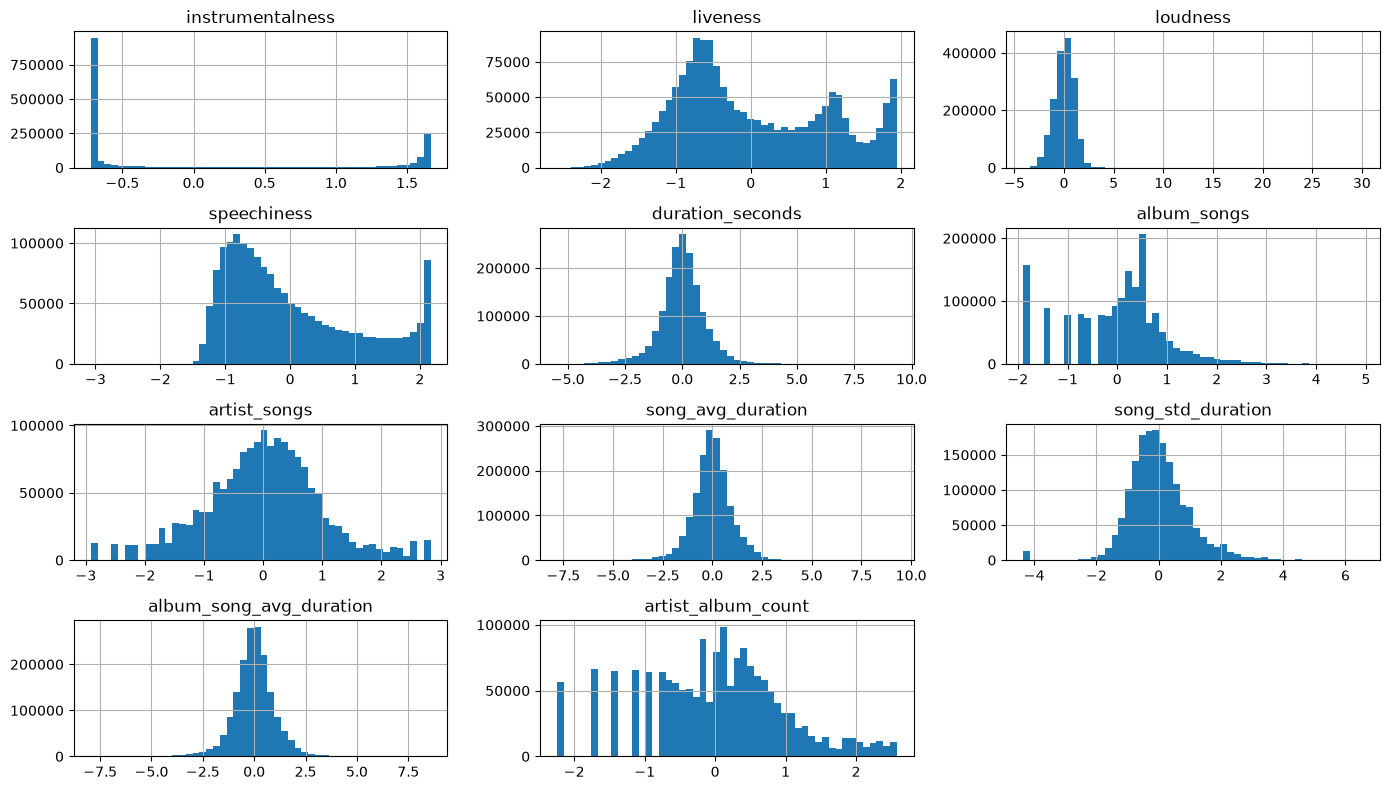

In [81]:
X_train_numeric_cat[skewed_features].hist(bins=50, figsize=(14, 8))

plt.tight_layout()
plt.show()

In [82]:
X_train_numeric_cat.skew(numeric_only=True)

instrumentalness             0.837947
liveness                     0.365041
loudness                     0.063275
speechiness                  0.790988
duration_seconds             0.062942
album_songs                  0.009071
artist_songs                -0.018587
song_avg_duration           -0.014466
song_std_duration            0.140341
album_song_avg_duration     -0.026777
artist_album_count          -0.000069
acousticness                 0.371443
danceability                -0.216224
energy                      -0.323845
tempo                        0.360354
valence                      0.047722
key_0                        2.326683
key_1                        3.072114
key_2                        2.436723
key_3                        5.288434
key_4                        3.057297
key_5                        2.965738
key_6                        3.823938
key_7                        2.228516
key_8                        3.875086
key_9                        2.504535
key_10      

As shown in the histograms and skewness values above, our power transformation helped reduce the skewness of several numerical features. Standardization also centered the features around a mean of zero and scaled them to a standard deviation of one. These preprocessing steps make the features more suitable for PCA, which analyzes variation around the mean and can be influenced by differences in feature scales.

In [36]:
pca = PCA().set_output(transform='pandas')

In [42]:
X_train_pca = pca.fit_transform(X_train_numeric_cat)
X_validation_pca = pca.transform(X_validation_numeric_cat)
X_test_pca = pca.transform(X_test_numeric_cat)

NameError: name 'pca' is not defined

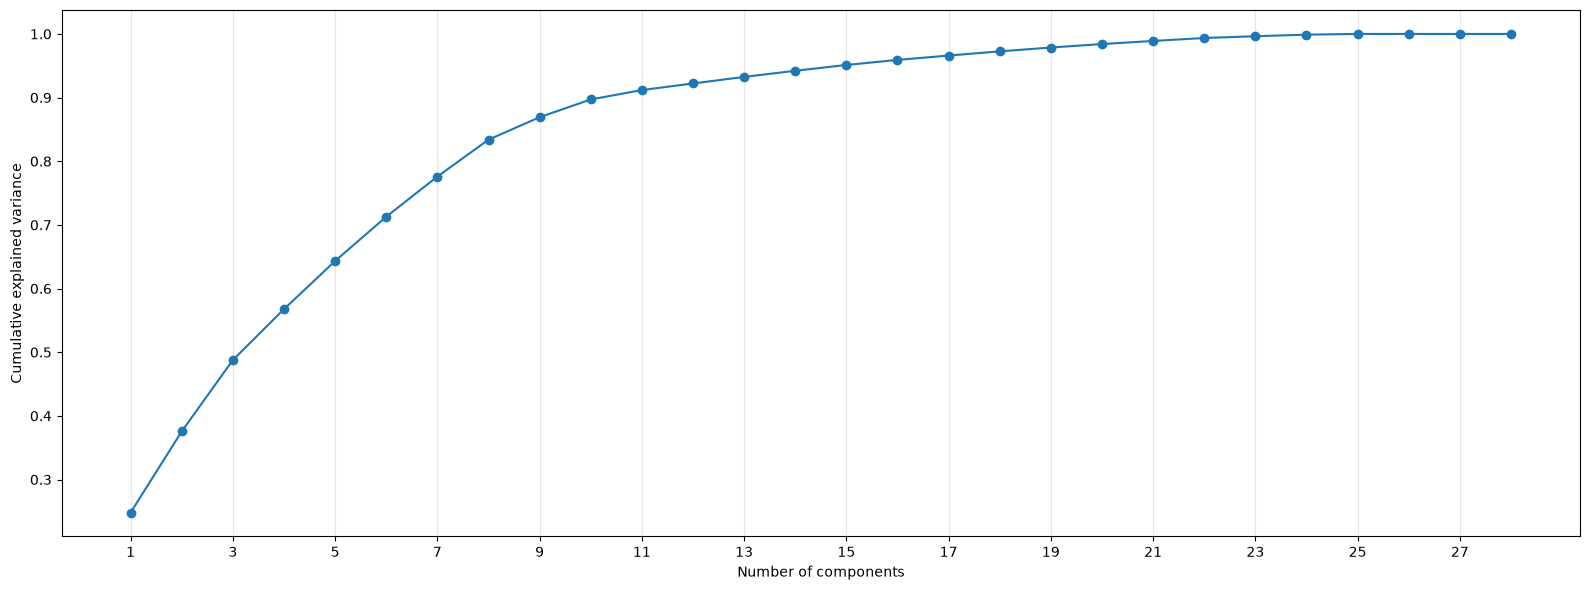

In [41]:
plt.figure(figsize=(16, 6))

explained_variance = np.cumsum(pca.explained_variance_ratio_)

plt.plot(range(1, len(explained_variance) + 1), explained_variance, marker='o')

plt.xticks(range(1, len(explained_variance) + 1, 2))
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [86]:
pca = PCA(n_components=13).set_output(transform='pandas')

In [87]:
X_train_pca = pca.fit_transform(X_train_numeric_cat)
X_validation_pca = pca.transform(X_validation_numeric_cat)
X_test_pca = pca.transform(X_test_numeric_cat)

In [97]:
print(f'Variance: {100 * np.cumsum(pca.explained_variance_ratio_)[-1]:.2f}%')
print(f'Number of features: {X_train_pca.shape[1]}')

Variance: 93.25%
Number of features: 13


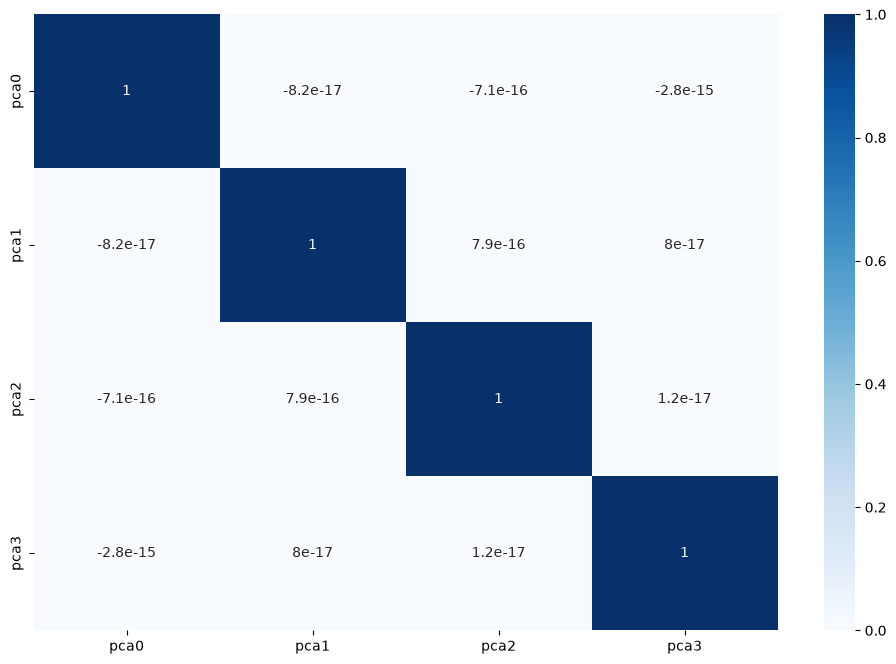

In [43]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    X_train_pca[['pca0', 'pca1', 'pca2', 'pca3']].corr(),
    annot=True,
    cmap='Blues'
)

plt.show()

The correlation matrix shows that the principal components are approximately **uncorrelated**, with correlations close to zero. This is an expected result of **PCA**, which transforms the original features into new, orthogonal components. This means the components capture different directions of variation in the data, with minimal linear correlation between them.

However, this PCA was performed only on our non-sparse audio features. Standard PCA is not suitable for our combined sparse dataset, which also includes TF-IDF text features. To reduce the dimensionality of this sparse data efficiently, we can use **TruncatedSVD** instead.

In [83]:
svd = TruncatedSVD(n_components=128, random_state=42)

In [84]:
X_train_svd = svd.fit_transform(X_train_transformed)
X_validation_svd = svd.transform(X_validation_transformed)
X_test_svd = svd.transform(X_test_transformed)

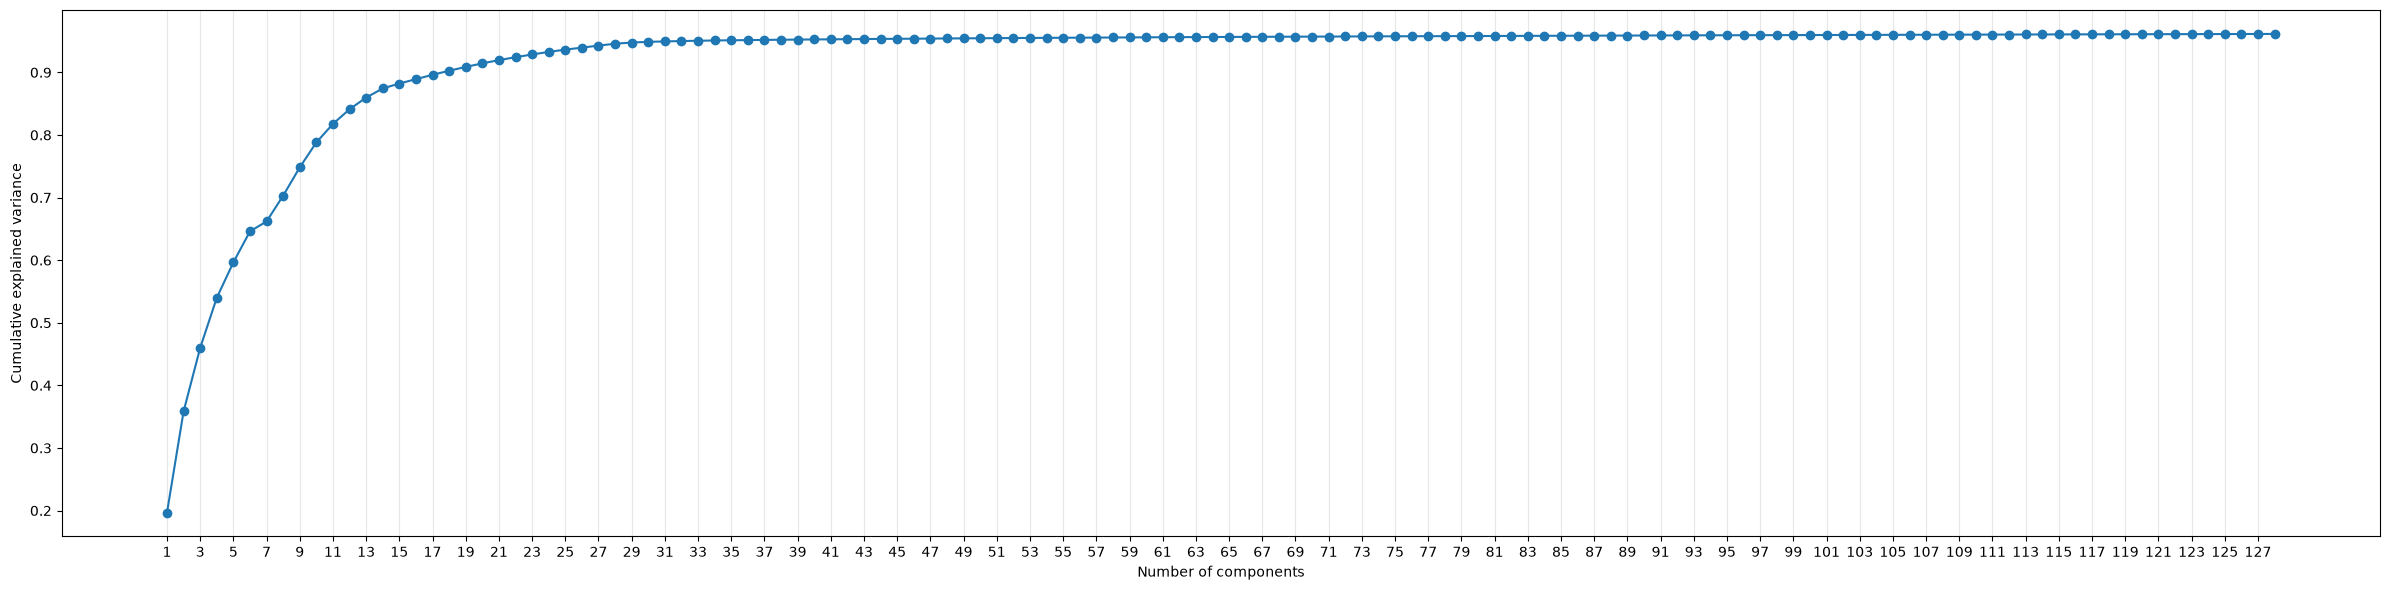

In [85]:
plt.figure(figsize=(24, 6))

explained_variance = np.cumsum(svd.explained_variance_ratio_)

plt.plot(range(1, len(explained_variance) + 1), explained_variance, marker='o')

plt.xticks(range(1, len(explained_variance) + 1, 2))
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [86]:
svd = TruncatedSVD(n_components=31, random_state=42)

In [89]:
X_train_svd = svd.fit_transform(X_train_transformed)
X_validation_svd = svd.transform(X_validation_transformed)
X_test_svd = svd.transform(X_test_transformed)

In [90]:
print(f'Variance: {100 * np.cumsum(svd.explained_variance_ratio_)[-1]:.2f}%')
print(f'Number of features: {X_train_svd.shape[1]}')

Variance: 94.95%
Number of features: 31


By reducing our feature space from **5,028** features to just **29** components using TruncatedSVD, we retain approximately **93%** of the explained variance. This substantially reduces the dimensionality of our data, helping mitigate the curse of dimensionality and making further analysis and modelling more computationally efficient.

In [91]:
svd_columns = [f"svd{i+1}" for i in range(X_train_svd.shape[1])]

sample_df = pd.DataFrame(
    X_train_svd,
    columns=svd_columns
)

sample_df['genre'] = np.asarray(y_train)

In [92]:
sample_df = (
    sample_df.groupby("genre", group_keys=False)
    .sample(n=50, random_state=42)
    .reset_index(drop=True)
)

X_sample = sample_df[svd_columns]
y_sample = sample_df["genre"]

We took 50 samples per `genre` class, to visualize our data in 2D, with our most important first and second SVD component on our plot. 

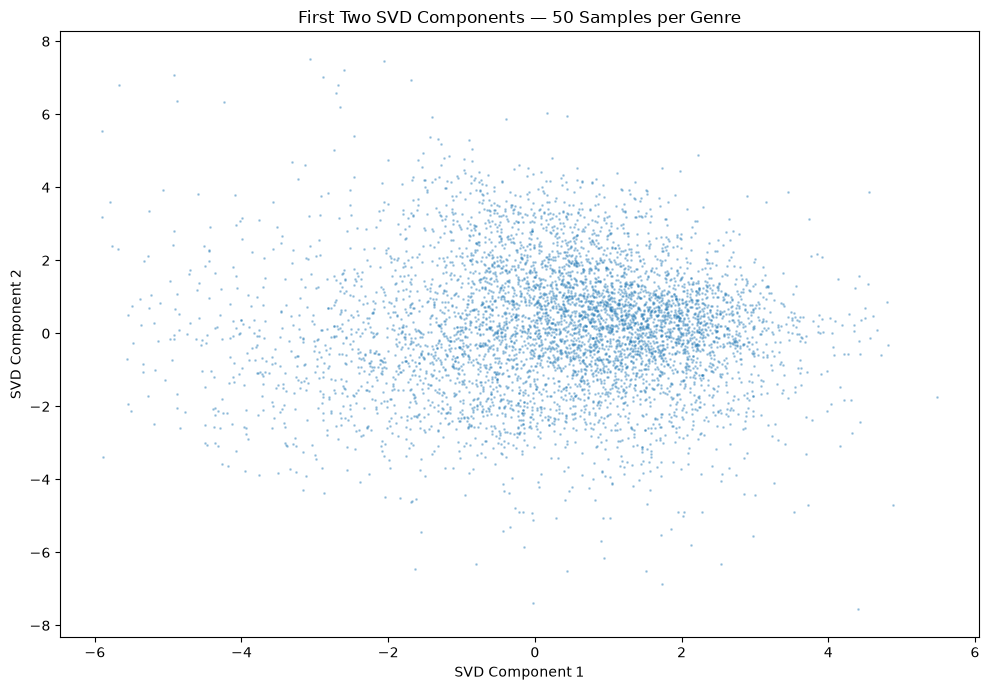

In [93]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X_sample['svd1'],
    X_sample['svd2'],
    s=1,
    alpha=0.3
)

plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.title("First Two SVD Components — 50 Samples per Genre")
plt.tight_layout()
plt.show()

### 1.2.6 Clustering

We observed a substantial class imbalance in our genre labels: the smallest genre contains only 66 tracks, while the largest contains 48,143. This imbalance can make genre classification more challenging, as models may perform better on well-represented genres than on underrepresented ones.

Next, we use **clustering** to identify groups of similar tracks and examine their genre distributions. This helps us explore whether similar genres could be combined into broader categories.

In [94]:
svd_columns = [f"svd{i+1}" for i in range(X_train_svd.shape[1])]

genre_means = pd.DataFrame(
    X_train_svd,
    columns=svd_columns
).groupby(np.asarray(y_train)).mean()

#### K-Means Clustering:

In [95]:
sse = []

for k in range(1, len(genre_means) + 1):
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(genre_means[['svd1', 'svd2', 'svd3', 'svd4']])
    sse.append(kmeans.inertia_)

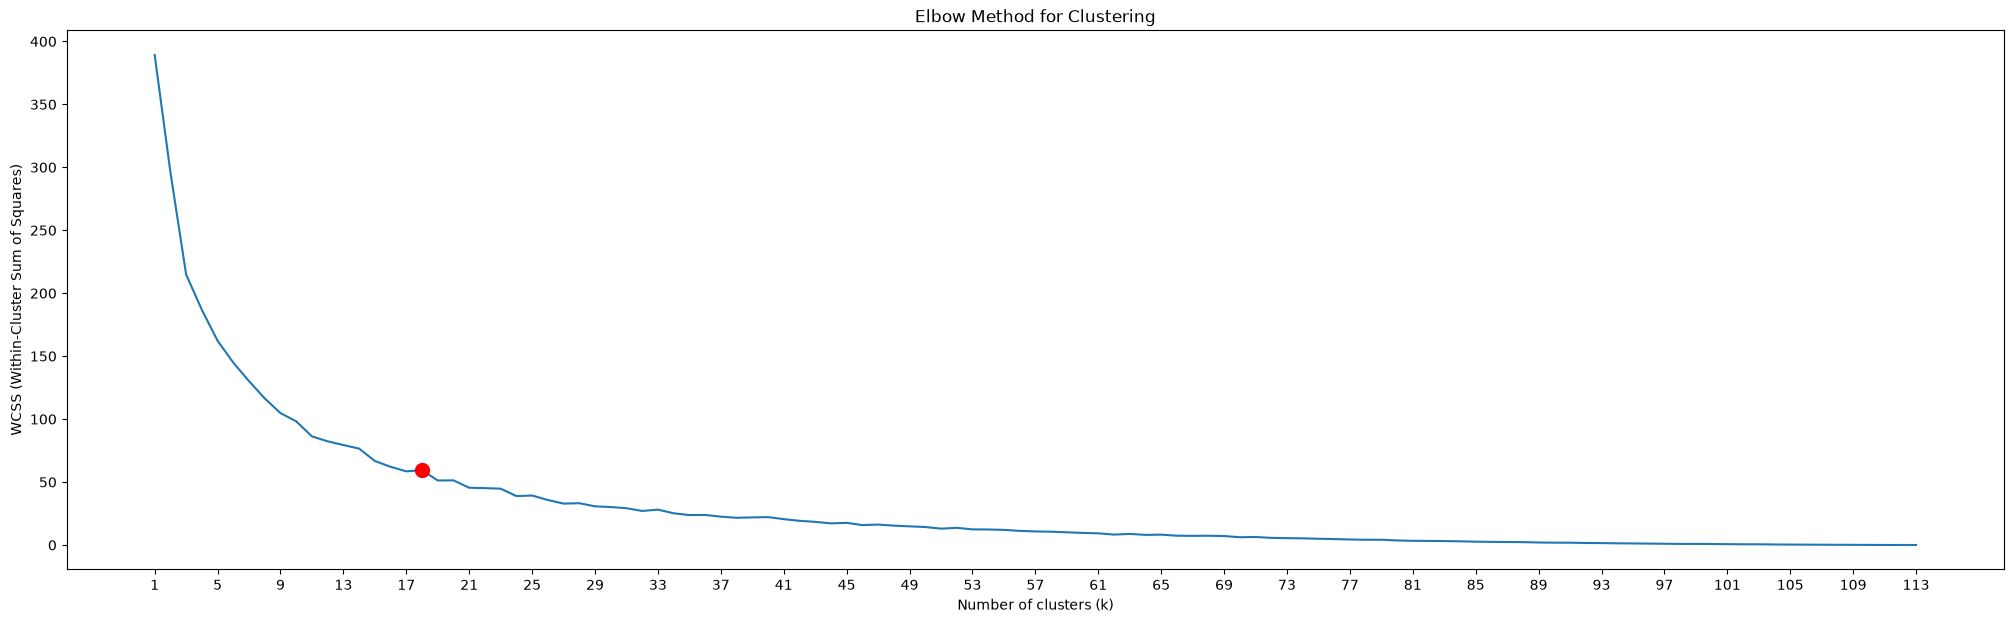

In [96]:
plt.figure(figsize=(25, 7))
plt.plot(range(1, len(genre_means) + 1), sse)

plt.scatter(18, sse[18 - 1], color='red', s=100, zorder=5)

plt.title('Elbow Method for Clustering')
plt.xlabel('Number of clusters (k)')
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')
plt.xticks(range(1, len(genre_means) + 1, 4))

plt.show()

In [97]:
silhouette_scores = []

for k in range(2, len(genre_means)):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(genre_means[['svd1', 'svd2', 'svd3', 'svd4']])

    score = silhouette_score(
        genre_means[['svd1', 'svd2', 'svd3', 'svd4']],
        labels
    )
    silhouette_scores.append(score)

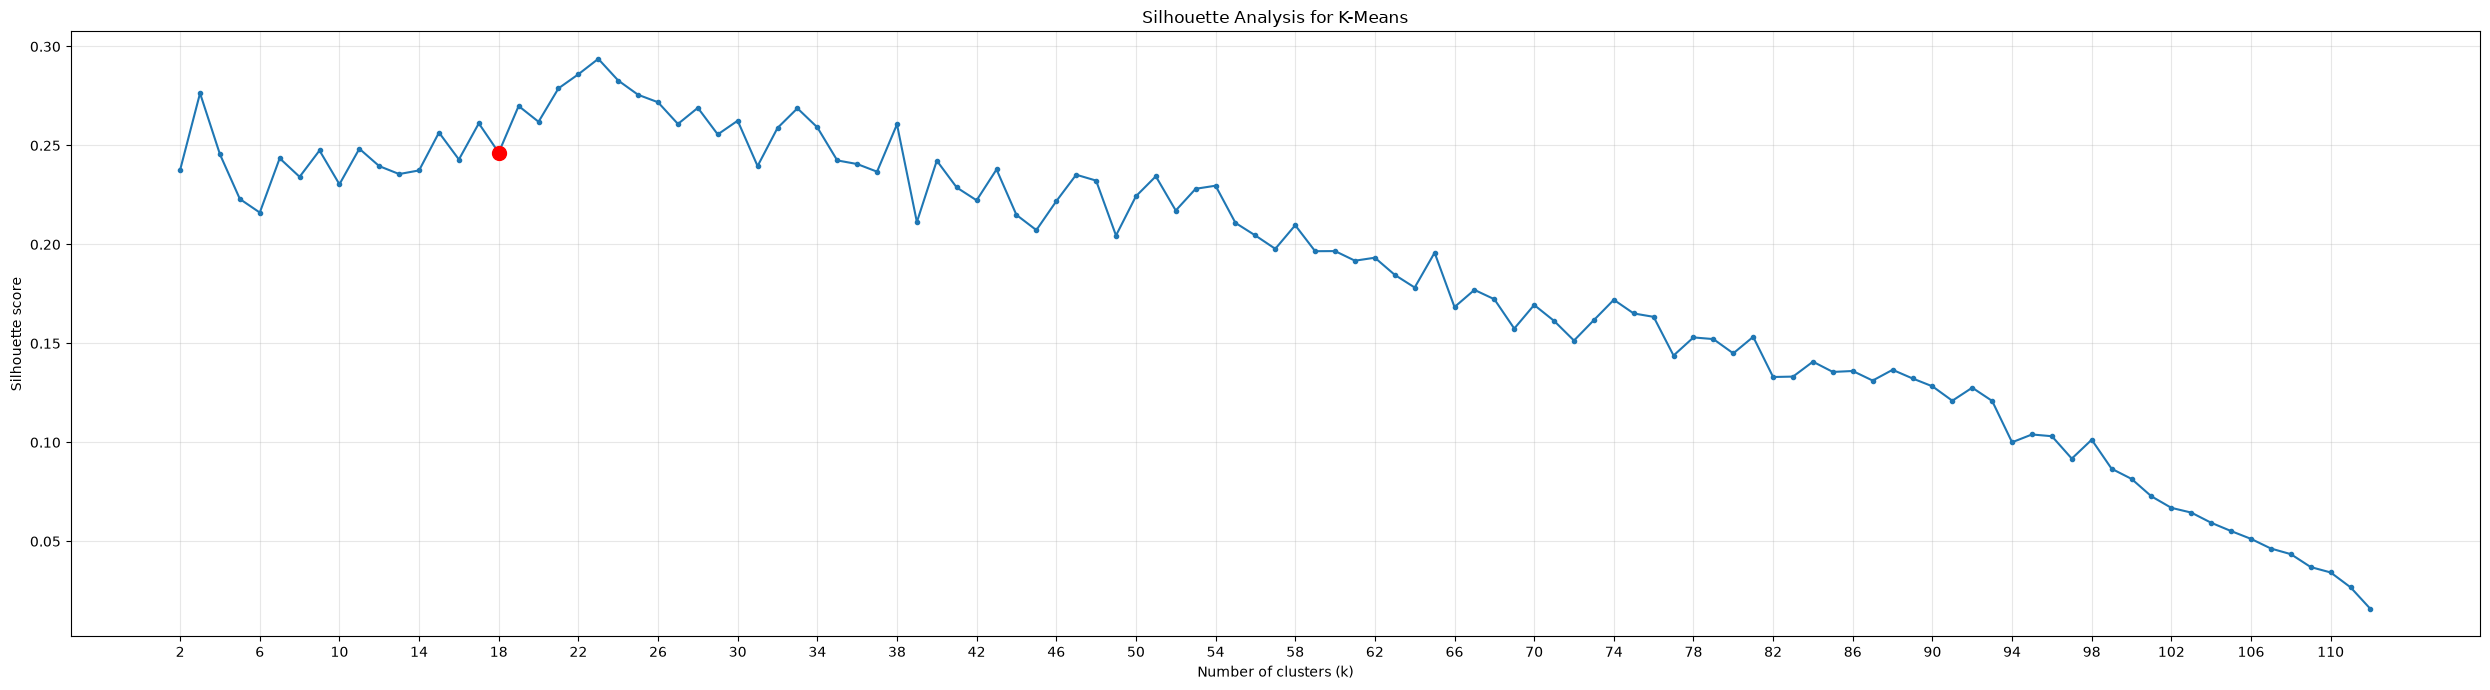

In [98]:
k_values = range(2, len(genre_means))

plt.figure(figsize=(25, 7))
plt.plot(k_values, silhouette_scores, marker='o', markersize=3)

plt.scatter(18, silhouette_scores[18 - 2], color='red', s=100, zorder=5)

plt.title('Silhouette Analysis for K-Means')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette score')

plt.xticks(range(2, len(genre_means), 4))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
km = KMeans(n_clusters=18, random_state=42, n_init=10)

In [116]:
genre_means['cluster'] = km.fit_predict(
    genre_means
)

In [117]:
genre_means.head()

,svd1,svd2,svd3,svd4,svd5,svd6,svd7,svd8,svd9,svd10,svd11,svd12,svd13,svd14,svd15,svd16,svd17,svd18,svd19,svd20,svd21,svd22,svd23,cluster
0,-0.805409,0.493689,-0.242742,0.044210,-0.239942,0.198746,-0.145135,0.019510,0.064730,0.185323,-0.068562,0.125964,-0.012342,0.025227,0.047669,0.004395,-0.017095,-0.012516,0.006785,0.010542,-0.000127,-0.006500,-0.023330,11
1,0.784856,0.181748,-0.662196,-0.005864,0.325136,-0.158296,0.553240,0.063794,-0.282309,-0.039192,-0.029923,0.085602,-0.010478,0.043223,0.012535,0.005982,-0.007423,-0.006693,0.003871,0.004987,0.007883,0.012407,-0.011360,13
2,0.677597,-0.283161,0.331524,0.264399,-0.432143,-0.302090,-0.068796,0.090165,0.076212,-0.189594,-0.008014,0.106596,0.008471,0.036323,0.019123,0.007431,-0.017307,-0.008733,-0.003003,0.001237,0.008221,0.003589,-0.018548,8
3,0.972665,-0.000966,0.262756,-0.230739,0.287496,-0.198818,-0.351870,0.267808,0.155656,0.010334,-0.103929,0.107065,0.001808,0.021564,0.012140,0.015748,-0.023267,-0.008147,-0.000599,0.000801,0.012105,0.000676,-0.018381,6
4,-2.511484,-1.209242,-0.204182,0.102001,0.393891,-0.103471,0.158148,-0.062311,-0.077046,-0.120632,0.014446,0.097324,0.021231,0.029447,0.003546,0.005948,-0.013900,0.000781,0.010176,-0.003603,-0.003272,0.002731,-0.009442,7


In [118]:
for cluster in sorted(genre_means['cluster'].unique()):
    encoded_genres = genre_means.index[
        genre_means['cluster'] == cluster
    ].to_numpy(dtype=int)

    genres = le.inverse_transform(encoded_genres)

    print(f"Cluster {cluster + 1}: [{', '.join(genres)}]")

Cluster 1: [bluegrass, honky-tonk, r-n-b, rock-n-roll, samba]
Cluster 2: [idm, iranian]
Cluster 3: [blues, brazil, country, indie, indie-pop, j-pop, j-rock, k-pop, latin, malay, psych-rock, rock, spanish, swedish]
Cluster 4: [british, disney, french, german, romance, show-tunes, tango]
Cluster 5: [drum-and-bass, happy, hardstyle]
Cluster 6: [chicago-house, deep-house, detroit-techno, house, minimal-techno]
Cluster 7: [alternative, sad]
Cluster 8: [ambient, classical, new-age, opera, sleep]
Cluster 9: [alt-rock, anime, emo, garage, goth, power-pop, punk, punk-rock, ska]
Cluster 10: [grindcore]
Cluster 11: [grunge, hard-rock, hardcore, heavy-metal, metal, metalcore]
Cluster 12: [acoustic, cantopop, folk, gospel, indian, mandopop, mpb, pop, pop-film, singer-songwriter, songwriter, soul, turkish, world-music]
Cluster 13: [comedy]
Cluster 14: [afrobeat, dance, disco, funk, j-dance, reggae, synth-pop]
Cluster 15: [dancehall, hip-hop, latino, reggaeton]
Cluster 16: [black-metal, death-metal]


In [ ]:
genre_to_cluster = genre_means['cluster'].to_dict()

In [125]:
y_train_cluster = pd.Series(y_train).map(genre_to_cluster).to_numpy()
y_test_cluster = pd.Series(y_test).map(genre_to_cluster).to_numpy()

In [99]:
def evaluate_model(model, X, y):
    y_pred = model.predict(X)

    accuracy = accuracy_score(y, y_pred)
    macro_f1 = f1_score(y, y_pred, average="macro")

    print(f"Accuracy: {accuracy:.2f}")
    print(f"Macro-F1: {macro_f1:.4f}")

In [122]:
rf = RandomForestClassifier(random_state=42)

In [ ]:
rf.fit(X_train_svd, y_train_cluster)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [127]:
evaluate_model(rf, X_test_svd, y_test_cluster)

Accuracy: 0.41
Macro-F1: 0.3914


In [ ]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_svd, y_train_cluster)

evaluate_model(dummy, X_test_svd, y_test_cluster)

Accuracy: 0.16
Macro-F1: 0.0122


Our baseline classifier achieved an accuracy of 0.16, whereas our Random Forest model achieved an accuracy of 0.41 using K-Means clustering to group the original 113 genres into 22 clusters. This substantial improvement suggests that the model learns useful patterns from the input features to predict the assigned genre clusters, rather than simply predicting the most frequent class. Macro-F1 should also be considered to evaluate performance across clusters, particularly given potential class imbalance.

#### Hierachical Clustering:

In [100]:
linkage_data = linkage(
    genre_means[['svd1', 'svd2', 'svd3', 'svd4']],
    method="ward",
    metric="euclidean"
)

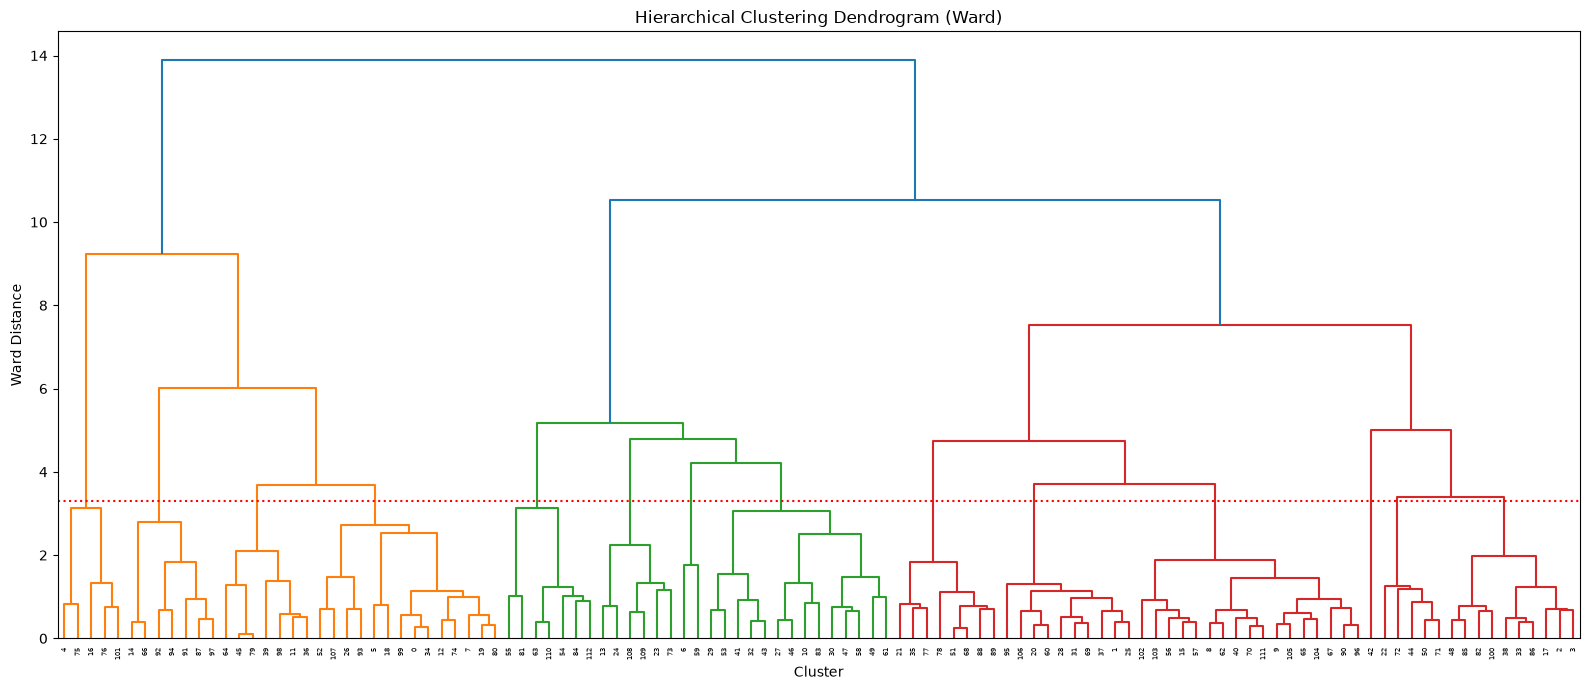

In [101]:
plt.figure(figsize=(16, 7))

dendrogram(linkage_data)

plt.axhline(y=3.3, color='red', linestyle=':', linewidth=1.5)

plt.title("Hierarchical Clustering Dendrogram (Ward)")
plt.xlabel("Cluster")
plt.ylabel("Ward Distance")
plt.tight_layout()
plt.show()

We apply agglomerative hierarchical clustering to group the 113 genres into 11 clusters based on their mean SVD representations. Starting with each genre as its own cluster, Ward’s linkage iteratively merges the two clusters that produce the smallest increase in total within-cluster variance. This encourages compact clusters with similar genre representations. The process continues until the specified number of 11 clusters is reached.

In [102]:
hierarchical_cluster = AgglomerativeClustering(n_clusters=14, linkage='ward')

In [103]:
hierarchical_labels = hierarchical_cluster.fit_predict(genre_means)

In [104]:
genre_means["hierarchical_cluster"] = hierarchical_labels

In [105]:
for cluster in sorted(genre_means['hierarchical_cluster'].unique()):
    encoded_genres = genre_means.index[
        genre_means['hierarchical_cluster'] == cluster
    ].to_numpy(dtype=int)

    genres = le.inverse_transform(encoded_genres)

    print(f"Cluster {cluster + 1}: [{', '.join(genres)}]")

Cluster 1: [afrobeat, alt-rock, anime, chill, club, dance, disco, dub, electro, electronic, funk, goth, groove, grunge, hard-rock, idm, industrial, j-dance, j-rock, psych-rock, salsa, synth-pop, trip-hop, world-music]
Cluster 2: [black-metal, death-metal, heavy-metal, iranian, metal, metalcore]
Cluster 3: [british, disney, french, german, guitar, jazz, piano, romance, show-tunes, tango]
Cluster 4: [chicago-house, deep-house, detroit-techno, dubstep, house, minimal-techno, techno, trance]
Cluster 5: [bluegrass, forro, honky-tonk, pagode, r-n-b, rock-n-roll, rockabilly, sertanejo]
Cluster 6: [dancehall, hip-hop, j-idol, latino, party, reggae, reggaeton, sad]
Cluster 7: [ambient, classical, new-age, opera, sleep]
Cluster 8: [grindcore]
Cluster 9: [acoustic, blues, brazil, cantopop, country, folk, gospel, indie, indie-pop, j-pop, k-pop, latin, malay, mandopop, mpb, pop, rock, samba, singer-songwriter, songwriter, soul, spanish, swedish, turkish]
Cluster 10: [indian, pop-film]
Cluster 11: [

In [106]:
genre_to_hierarchical_cluster = genre_means['hierarchical_cluster'].to_dict()

In [107]:
X_sample = X_sample.copy()

X_sample['hierarchical_cluster'] = y_sample.map(
    genre_to_hierarchical_cluster
).to_numpy()

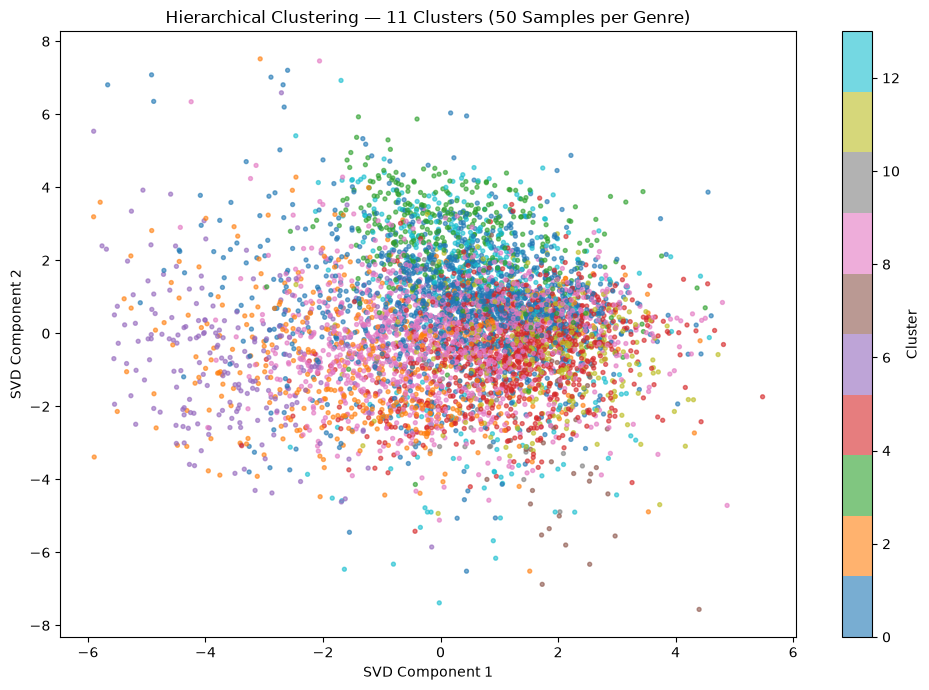

In [108]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_sample["svd1"],
    X_sample["svd2"],
    c=X_sample["hierarchical_cluster"],
    cmap="tab10",
    s=8,
    alpha=0.6
)

plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.title("Hierarchical Clustering — 11 Clusters (50 Samples per Genre)")

plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

In [127]:
y_train_hierarchical = (pd.Series(y_train).map(genre_to_hierarchical_cluster).to_numpy())
y_validation_hierarchical = (pd.Series(y_validation).map(genre_to_hierarchical_cluster).to_numpy())
y_test_hierarchical = (pd.Series(y_test).map(genre_to_hierarchical_cluster).to_numpy())

In [ ]:
rf = RandomForestClassifier(random_state=42)

In [153]:
rf.fit(X_train_svd, y_train_hierarchical)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [154]:
evaluate_model(rf, X_test_svd, y_test_hierarchical)

Accuracy: 0.45
Macro-F1: 0.4475


In [155]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_svd, y_train_cluster)

evaluate_model(dummy, X_test_svd, y_test_hierarchical)

Accuracy: 0.12
Macro-F1: 0.0196


Our baseline classifier achieved an accuracy of 0.12, whereas our Decision Tree model achieved an accuracy of 0.45 using hierarchical clustering to group the original 113 genres into 11 clusters. This substantial improvement suggests that the model learns useful patterns from the input features to predict the assigned genre clusters, rather than simply predicting the most frequent class. Macro-F1 should also be considered to evaluate performance across clusters, particularly given potential class imbalance.

In [159]:
y_pred = rf.predict(X_test_svd)

NameError: name 'y_pred' is not defined

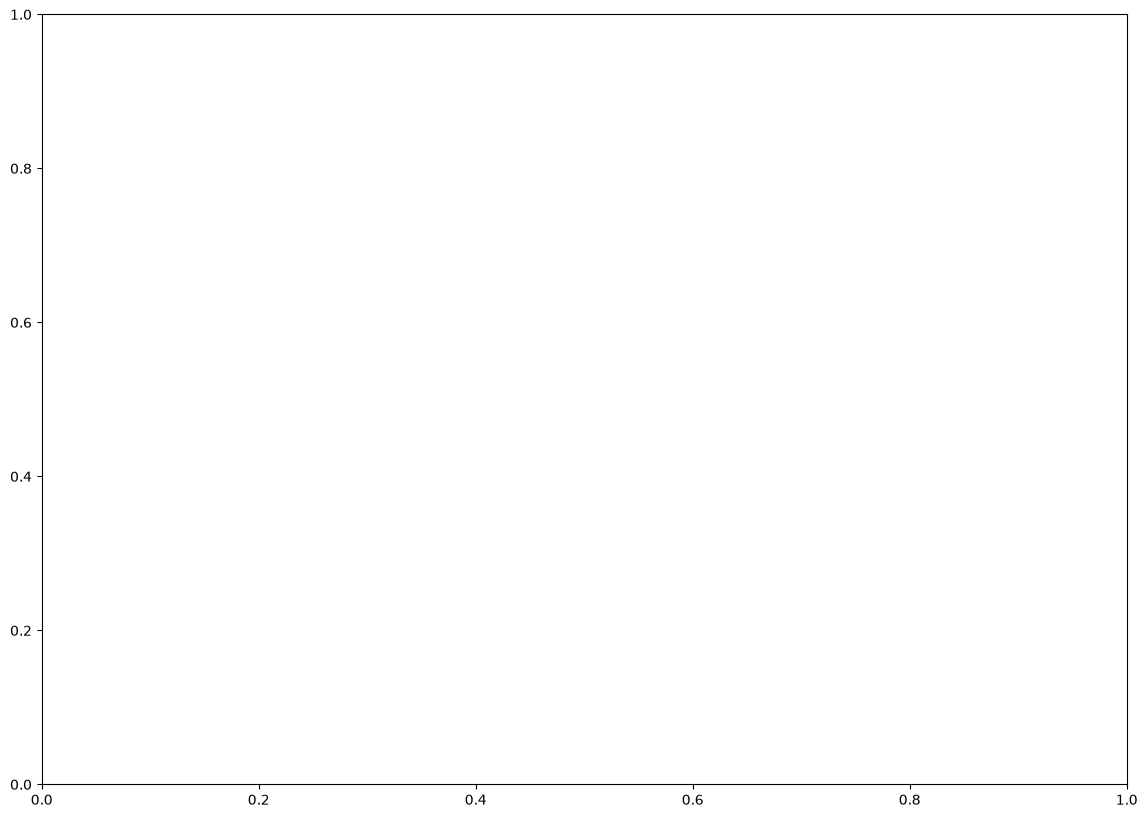

In [59]:
fig, ax = plt.subplots(figsize=(14, 10))

ConfusionMatrixDisplay.from_predictions(
    y_test_hierarchical,
    y_pred,
    normalize="true",
    cmap="Blues",
    values_format=".2f",
    ax=ax
)

ax.set_title("Random Forest — Hierarchical Clusters")
plt.tight_layout()
plt.show()

In [110]:
cluster_distribution = pd.Series(y_train_hierarchical).value_counts().sort_index()

cluster_summary = pd.DataFrame({
    "track_count": cluster_distribution,
    "percentage": cluster_distribution / len(y_train_hierarchical) * 100
})

print(cluster_summary.round(2))

    track_count  percentage
0        362880       21.47
1         58862        3.48
2        195610       11.57
3         61661        3.65
4        115074        6.81
5         64665        3.83
6        127154        7.52
7         11171        0.66
8        438285       25.93
9         60708        3.59
10        16953        1.00
11       100113        5.92
12        52837        3.13
13        24203        1.43


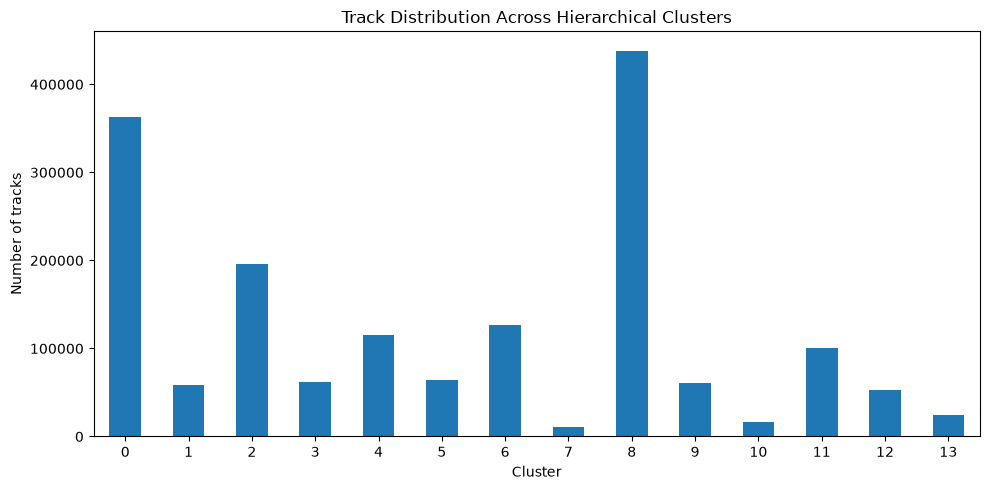

In [111]:
cluster_summary["track_count"].plot(kind="bar", figsize=(10, 5))

plt.title("Track Distribution Across Hierarchical Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of tracks")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 2. Model Development and Evaluation

## 2.1 Baseline Model Training and Evaluation

After having created clusters of our genres, 

### 2.1.3 Ensemble Model

In [112]:
cb_model = CatBoostClassifier(task_type='GPU', devices='0')

In [ ]:
cb_model.fit(X_train_svd, y_train_hierarchical)

Learning rate set to 0.295653
0:	learn: 2.0749431	total: 82.2ms	remaining: 1m 22s
1:	learn: 1.8869801	total: 99.3ms	remaining: 49.5s
2:	learn: 1.7856417	total: 116ms	remaining: 38.5s
3:	learn: 1.7099518	total: 133ms	remaining: 33.1s
4:	learn: 1.6539816	total: 150ms	remaining: 29.9s
5:	learn: 1.6110287	total: 167ms	remaining: 27.6s
6:	learn: 1.5766549	total: 184ms	remaining: 26.2s
7:	learn: 1.5432569	total: 203ms	remaining: 25.1s
8:	learn: 1.5213478	total: 219ms	remaining: 24.2s
9:	learn: 1.4994459	total: 238ms	remaining: 23.5s
10:	learn: 1.4839832	total: 255ms	remaining: 22.9s
11:	learn: 1.4688717	total: 272ms	remaining: 22.4s
12:	learn: 1.4563516	total: 288ms	remaining: 21.8s
13:	learn: 1.4432211	total: 305ms	remaining: 21.5s
14:	learn: 1.4320472	total: 323ms	remaining: 21.2s
15:	learn: 1.4220411	total: 340ms	remaining: 20.9s
16:	learn: 1.4133892	total: 357ms	remaining: 20.6s
17:	learn: 1.4054733	total: 373ms	remaining: 20.3s
18:	learn: 1.3992429	total: 389ms	remaining: 20.1s
19:	lear

CatBoostClassifier(devices='0', task_type='GPU')

In [132]:
evaluate_model(cb_model, X_test_svd, y_test_hierarchical)

Accuracy: 0.57
Macro-F1: 0.6136


In [116]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_svd, y_train_hierarchical)

evaluate_model(dummy, X_test_svd, y_test_hierarchical)

Accuracy: 0.26
Macro-F1: 0.0294


## 2.2 Model optimization

In [64]:
X_validation_svd

array([[-2.70686109e+00, -2.56160123e-03,  2.74313961e+00, ...,
         1.34982531e-02, -8.75552023e-03,  9.25661918e-02],
       [-3.92682139e+00, -8.01474156e-01,  6.36078336e-01, ...,
         1.65414680e-02,  5.34654853e-02, -6.89653605e-02],
       [-4.68615866e+00, -1.10340603e+00,  1.46431950e+00, ...,
         5.07075582e-02,  9.42314988e-02,  1.12488000e-02],
       ...,
       [-3.99889177e+00,  6.98587721e-01,  4.09854003e-01, ...,
        -1.41558626e-02, -8.35565813e-03, -9.04726492e-02],
       [-3.72065808e+00, -1.88746738e+00, -7.56753420e-01, ...,
        -3.38529920e-02,  1.42519180e-02,  2.61563944e-02],
       [-4.69175385e+00, -1.33121542e+00, -5.92275623e-01, ...,
        -2.01813518e-02, -3.10970836e-02, -1.04487813e-02]],
      shape=(211272, 29))

In [63]:
evaluate_model(cb_model, X_test_svd, y_test_hierarchical)

Accuracy: 0.56
Macro-F1: 0.5465


We use **Optuna** with Bayesian Optimization to tune our model hyperparameters. Unlike grid search, which exhaustively evaluates predefined combinations, or random search, which samples configurations independently, Optuna uses previous trial results to guide subsequent searches.

This makes it particularly useful for computationally expensive models. Our objective is to maximize the validation **macro-F1** score while minimizing tuning time.

#### Logistic Regression

In [135]:
def objective(trial):
    params = {
        'iterations': trial.suggest_int('iterations', 100, 1500),
        'depth': trial.suggest_int('depth', 3, 10),
        "learning_rate": trial.suggest_float('learning_rate', 0.02, 0.15, log=True),
        'l2_leaf_reg': trial.suggest_int('l2_leaf_reg', 100, 1500),
        'loss_function': 'MultiClass',
        'eval_metric': 'TotalF1:average=Macro',
        'random_seed': 42,
        'verbose': False,
    }

    model = CatBoostClassifier(**params, task_type='GPU', devices='0')

    model.fit(
        X_train_svd,
        y_train_hierarchical,
        eval_set=(X_validation_svd, y_validation_hierarchical),
        use_best_model=True,
        early_stopping_rounds=50,
    )

    predictions = model.predict(X_validation_svd).ravel()

    macro_f1 = f1_score(
        y_validation_hierarchical,
        predictions,
        average="macro",
    )

    return macro_f1

In [ ]:
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=50)

print("Best macro-F1:", study.best_value)
print("Best parameters:", study.best_params)

[I 2026-10-27 12:21:22,323] A new study created in memory with name: no-name-5d423ada-fb4f-4218-ae45-1e1357cdd328
[I 2026-10-27 12:21:46,960] Trial 0 finished with value: 0.5672065424802817 and parameters: {'iterations': 449, 'depth': 10, 'learning_rate': 0.09510003307305125, 'l2_leaf_reg': 1374}. Best is trial 0 with value: 0.5672065424802817.
[I 2026-10-27 12:22:02,631] Trial 1 finished with value: 0.5603787489398299 and parameters: {'iterations': 1263, 'depth': 4, 'learning_rate': 0.05592172387839958, 'l2_leaf_reg': 1334}. Best is trial 0 with value: 0.5672065424802817.
[I 2026-10-27 12:22:15,528] Trial 2 finished with value: 0.5945242235651528 and parameters: {'iterations': 576, 'depth': 7, 'learning_rate': 0.11488374741535705, 'l2_leaf_reg': 110}. Best is trial 2 with value: 0.5945242235651528.
[I 2026-10-27 12:22:30,351] Trial 3 finished with value: 0.561416212027238 and parameters: {'iterations': 390, 'depth': 9, 'learning_rate': 0.08057326769482989, 'l2_leaf_reg': 1221}. Best i